# Machine Learning Capstone Project — Clustering Track
### 23CSE301 Machine Learning | Review 2 Evaluation
**Dataset**: Amazon Sales & Reviews Dataset (`amazon.csv`)  
**Objective**: End-to-end unsupervised clustering pipeline that segments Amazon India products by price, discount depth, rating and review volume. Category labels are never used during fitting (Guidelines §3.3); they are used only afterwards to validate the result.

**Algorithms**: K-Means and Agglomerative Hierarchical Clustering. **Metrics**: Silhouette, Davies-Bouldin, Calinski-Harabasz. **Visualisations**: Elbow curve, Dendrogram, PCA (all configurations), t-SNE, PCA biplot.

**Notebook map**: 1 Setup · 2 Data, cleaning & EDA · 3 Preprocessing & feature engineering · 4 K-Means · 5 Hierarchical · 6 Evaluation · 7 Best-model comparison · 8 PCA / t-SNE visualisation · 9 Segment interpretation · 10 Segment comparison · 11 Line graphs & CDFs · 12 Conclusion

## 1. Imports & Setup

In [1]:
import os
import warnings
warnings.filterwarnings('ignore')
os.environ['OMP_NUM_THREADS'] = '1'

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (silhouette_score, davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score, normalized_mutual_info_score)
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

# Plot configuration (colourblind-friendly palette, per guideline 7.3)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
PALETTE = sns.color_palette('colorblind')
print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Dataset Loading, Cleaning & Exploratory Data Analysis (EDA)

In [2]:
# Locate the dataset (repo layout: notebooks/ and data/ are sibling folders)
DATA_PATH = next(p for p in ['../data/amazon.csv', 'data/amazon.csv', 'amazon.csv'] if os.path.exists(p))
df_raw = pd.read_csv(DATA_PATH)
print("Loaded:", DATA_PATH)
print("Dataset Shape:", df_raw.shape)
df_raw.head(3)

Loaded: ../data/amazon.csv
Dataset Shape: (1465, 16)


,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,user_id,user_name,review_id,review_title,review_content,img_link,product_link
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,₹399,"₹1,099",64%,4.2,"24,269",High Compatibility : Compatible With iPhone 12...,"AG3D6O4STAQKAY2UVGEUV46KN35Q,AHMY5CWJMMK5BJRBB...","Manav,Adarsh gupta,Sundeep,S.Sayeed Ahmed,jasp...","R3HXWT0LRP0NMF,R2AJM3LFTLZHFO,R6AQJGUP6P86,R1K...","Satisfied,Charging is really fast,Value for mo...",Looks durable Charging is fine tooNo complains...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...
1,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,₹199,₹349,43%,4.0,"43,994","Compatible with all Type C enabled devices, be...","AECPFYFQVRUWC3KGNLJIOREFP5LQ,AGYYVPDD7YG7FYNBX...","ArdKn,Nirbhay kumar,Sagar Viswanathan,Asp,Plac...","RGIQEG07R9HS2,R1SMWZQ86XIN8U,R2J3Y1WL29GWDE,RY...","A Good Braided Cable for Your Type C Device,Go...",I ordered this cable to connect my phone to An...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Ambrane-Unbreakable-Char...
2,B096MSW6CT,Sounce Fast Phone Charging Cable & Data Sync U...,Computers&Accessories|Accessories&Peripherals|...,₹199,"₹1,899",90%,3.9,"7,928",【 Fast Charger& Data Sync】-With built-in safet...,"AGU3BBQ2V2DDAMOAKGFAWDDQ6QHA,AESFLDV2PT363T2AQ...","Kunal,Himanshu,viswanath,sai niharka,saqib mal...","R3J3EQQ9TZI5ZJ,R3E7WBGK7ID0KV,RWU79XKQ6I1QF,R2...","Good speed for earlier versions,Good Product,W...","Not quite durable and sturdy,https://m.media-a...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Sounce-iPhone-Charging-C...


In [3]:
# Data Audit: datatypes, missing values and uniqueness
audit = pd.DataFrame({
    'Data Type': df_raw.dtypes.astype(str),
    'Non-Null Count': df_raw.notnull().sum(),
    'Null Count': df_raw.isnull().sum(),
    'Unique Values': df_raw.nunique()
})
audit

,Data Type,Non-Null Count,Null Count,Unique Values
product_id,str,1465,0,1351
product_name,str,1465,0,1337
category,str,1465,0,211
discounted_price,str,1465,0,550
actual_price,str,1465,0,449
discount_percentage,str,1465,0,92
rating,str,1465,0,28
rating_count,str,1463,2,1143
about_product,str,1465,0,1293
user_id,str,1465,0,1194


**Observation (Audit):**
The file has 1,465 rows and 16 columns, but only **1,351 distinct `product_id` values**. Each row is one customer review, so a product appears several times. The numeric columns (`discounted_price`, `actual_price`, `discount_percentage`, `rating`, `rating_count`) are stored as text because of the `₹`, `,` and `%` characters. `rating` has one invalid entry (`'|'`) and `rating_count` has 2 missing values.

In [4]:
# Duplicate check. A full-row check misses repeated products, because each row of this
# dataset is a different customer review of a product, so the review columns always differ.
n_full_dup = df_raw.duplicated().sum()
n_id_dup = df_raw.duplicated(subset='product_id').sum()
print(f"Fully identical rows               : {n_full_dup}")
print(f"Rows repeating an earlier product_id: {n_id_dup}")

# Each product must be clustered once, so keep one row per product_id.
df = df_raw.drop_duplicates(subset='product_id', keep='first').reset_index(drop=True)
print(f"Rows before = {len(df_raw)}, rows after = {len(df)}, removed = {len(df_raw) - len(df)}")

Fully identical rows               : 0
Rows repeating an earlier product_id: 114
Rows before = 1465, rows after = 1351, removed = 114


**Observation (Duplicates):**
No row is fully identical, because the review columns differ. Even so, **114 rows repeat an earlier product**. Left in, these products would be counted several times and would pull the cluster centroids toward themselves. We keep one row per `product_id`, which leaves **1,351 products**.

In [5]:
# Data parsing: strip currency symbols, commas and % signs, then convert to numbers
df['discounted_price_clean'] = pd.to_numeric(
    df['discounted_price'].astype(str).str.replace('\u20b9', '', regex=False).str.replace(',', '', regex=False).str.strip(),
    errors='coerce')

df['actual_price_clean'] = pd.to_numeric(
    df['actual_price'].astype(str).str.replace('\u20b9', '', regex=False).str.replace(',', '', regex=False).str.strip(),
    errors='coerce')

df['discount_percentage_clean'] = pd.to_numeric(
    df['discount_percentage'].astype(str).str.replace('%', '', regex=False).str.strip(),
    errors='coerce')

# rating contains one invalid '|' entry -> NaN -> median imputation (robust to skew)
df['rating_clean'] = pd.to_numeric(df['rating'].replace('|', np.nan), errors='coerce')
print("Missing/invalid ratings imputed   :", df['rating_clean'].isna().sum())
df['rating_clean'] = df['rating_clean'].fillna(df['rating_clean'].median())

# rating_count has missing values -> median imputation
df['rating_count_clean'] = pd.to_numeric(
    df['rating_count'].astype(str).str.replace(',', '', regex=False).str.replace(' ', '', regex=False),
    errors='coerce')
print("Missing rating_count imputed      :", df['rating_count_clean'].isna().sum())
df['rating_count_clean'] = df['rating_count_clean'].fillna(df['rating_count_clean'].median())

# Top-level retail category. It is NOT used for clustering, only for post-hoc validation (Sec. 3.3).
df['main_category'] = df['category'].str.split('|').str[0].str.strip()

NUM_COLS = ['discounted_price_clean', 'actual_price_clean', 'discount_percentage_clean',
            'rating_clean', 'rating_count_clean']
df[NUM_COLS].describe().round(2)

Missing/invalid ratings imputed   : 1
Missing rating_count imputed      : 2


,discounted_price_clean,actual_price_clean,discount_percentage_clean,rating_clean,rating_count_clean
count,1351.00,1351.00,1351.00,1351.00,1351.00
mean,3304.80,5691.18,46.69,4.09,17625.39
std,7173.98,11218.67,21.63,0.30,42117.34
min,39.00,39.00,0.00,2.00,2.00
25%,349.00,899.00,31.00,3.90,1107.00
50%,899.00,1795.00,49.00,4.10,4740.00
75%,2174.00,4575.00,62.00,4.30,15995.00
max,77990.00,139900.00,94.00,5.00,426973.00


**Observation (Cleaning):**
Prices, discount and counts are now numeric. The one invalid rating and the two missing review counts are filled with the **median**, which is robust to the heavy skew. Review counts reach 426,973 against a median of 4,740, and selling prices reach ₹77,990 against a median of ₹899, so a mean fill would have been distorted.

### 2a. Feature Distributions, Outliers & Correlation

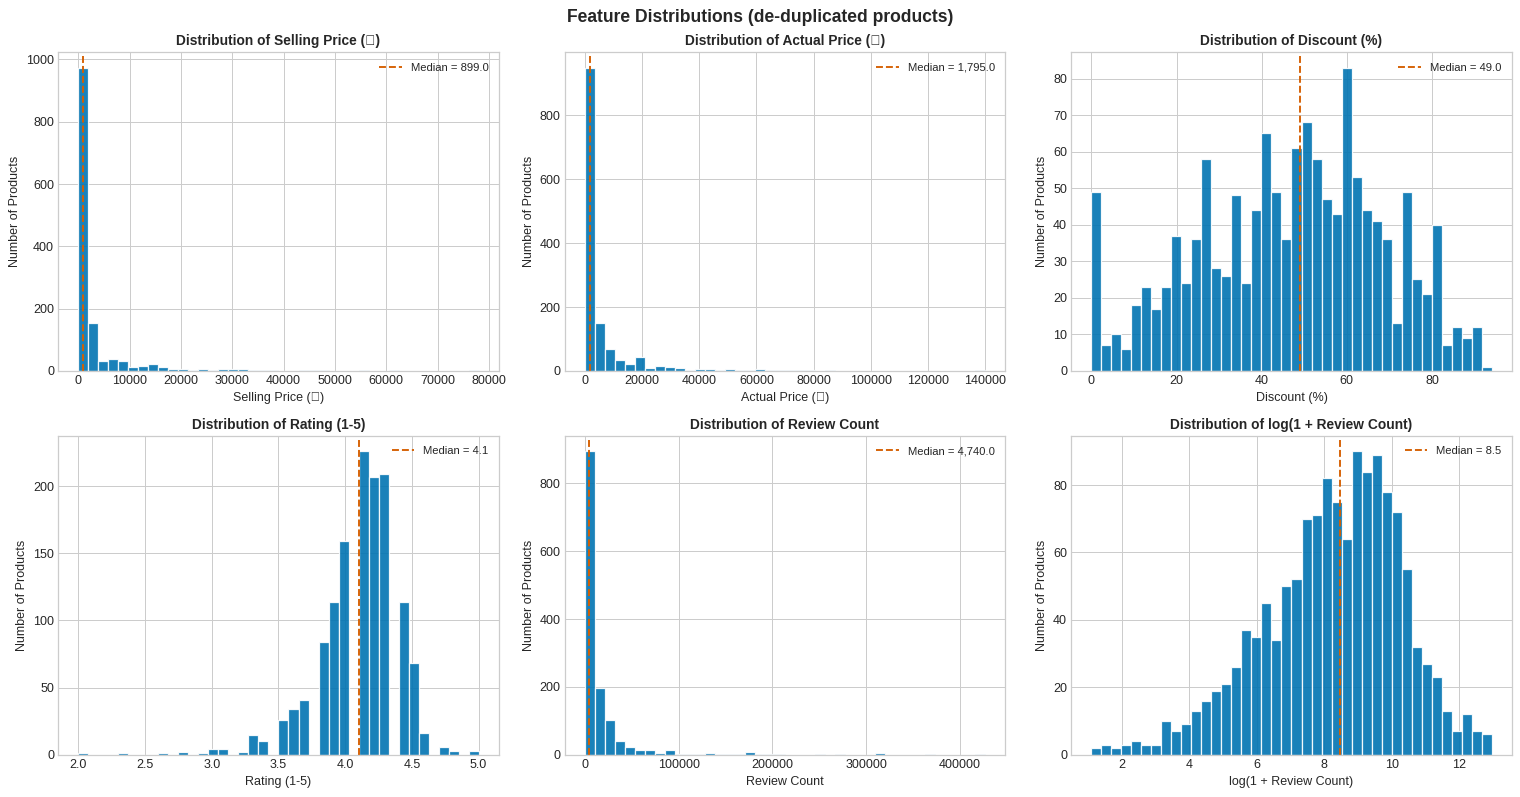

,Skewness,IQR outliers,Outliers (%)
Feature,,,
discounted_price_clean,4.30,209,15.47
actual_price_clean,4.43,185,13.69
discount_percentage_clean,-0.24,0,0.00
rating_clean,-1.23,19,1.41
rating_count_clean,5.69,130,9.62


In [6]:
# Distribution of every numeric feature, plus an IQR outlier audit
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
dist_specs = [
    ('discounted_price_clean', 'Selling Price (\u20b9)', df['discounted_price_clean']),
    ('actual_price_clean', 'Actual Price (\u20b9)', df['actual_price_clean']),
    ('discount_percentage_clean', 'Discount (%)', df['discount_percentage_clean']),
    ('rating_clean', 'Rating (1-5)', df['rating_clean']),
    ('rating_count_clean', 'Review Count', df['rating_count_clean']),
    ('log_rating_count_preview', 'log(1 + Review Count)', np.log1p(df['rating_count_clean'])),
]
for ax, (_, label, series) in zip(axes.flatten(), dist_specs):
    ax.hist(series, bins=40, color=PALETTE[0], edgecolor='white', alpha=0.9)
    ax.axvline(series.median(), color=PALETTE[3], linestyle='--', linewidth=1.5,
               label=f'Median = {series.median():,.1f}')
    ax.set_title(f'Distribution of {label}', fontweight='bold', fontsize=11)
    ax.set_xlabel(label)
    ax.set_ylabel('Number of Products')
    ax.legend(fontsize=9)
fig.suptitle('Feature Distributions (de-duplicated products)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# IQR outlier audit
rows = []
for col in NUM_COLS:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = int(((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum())
    rows.append({'Feature': col, 'Skewness': df[col].skew(), 'IQR outliers': n_out,
                 'Outliers (%)': 100 * n_out / len(df)})
pd.DataFrame(rows).set_index('Feature').round(2)

**Observation (Distributions & outliers):**
Prices (skewness ≈ 4.3–4.4) and review counts (skewness 5.7) are strongly right-skewed. By the IQR rule, 15.5% of selling prices, 13.7% of actual prices and 9.6% of review counts are outliers. Discount is roughly symmetric (median 49%, no outliers) and rating is left-skewed around 4.1 (1.4% outliers). These outliers are real products (premium electronics, best-sellers) rather than errors, so they are **kept** and the skew is handled with a log transform (Section 3). Removing them would delete the very segments we want to find. The log of the review count (last panel) is much less skewed (skewness ≈ −0.5) than the raw count (5.7).

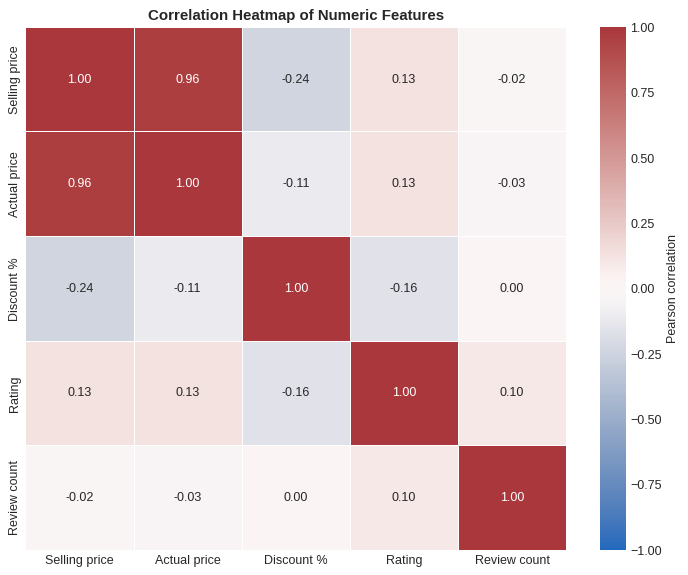

In [7]:
# Correlation heatmap of the raw numeric features
plt.figure(figsize=(8, 6.5))
corr_raw = df[NUM_COLS].corr()
sns.heatmap(corr_raw, annot=True, fmt='.2f', cmap='vlag', center=0, vmin=-1, vmax=1,
            linewidths=0.5, cbar_kws={'label': 'Pearson correlation'},
            xticklabels=['Selling price', 'Actual price', 'Discount %', 'Rating', 'Review count'],
            yticklabels=['Selling price', 'Actual price', 'Discount %', 'Rating', 'Review count'])
plt.title('Correlation Heatmap of Numeric Features', fontweight='bold')
plt.tight_layout()
plt.show()

**Observation (Correlation):**
Selling price and actual price are almost the same variable (r = 0.96). Discount is weakly negatively related to both prices (−0.24 and −0.11) and to rating (−0.16). Review count is essentially uncorrelated with every other feature. Only the two price columns are redundant, which drives the feature selection in Section 3.

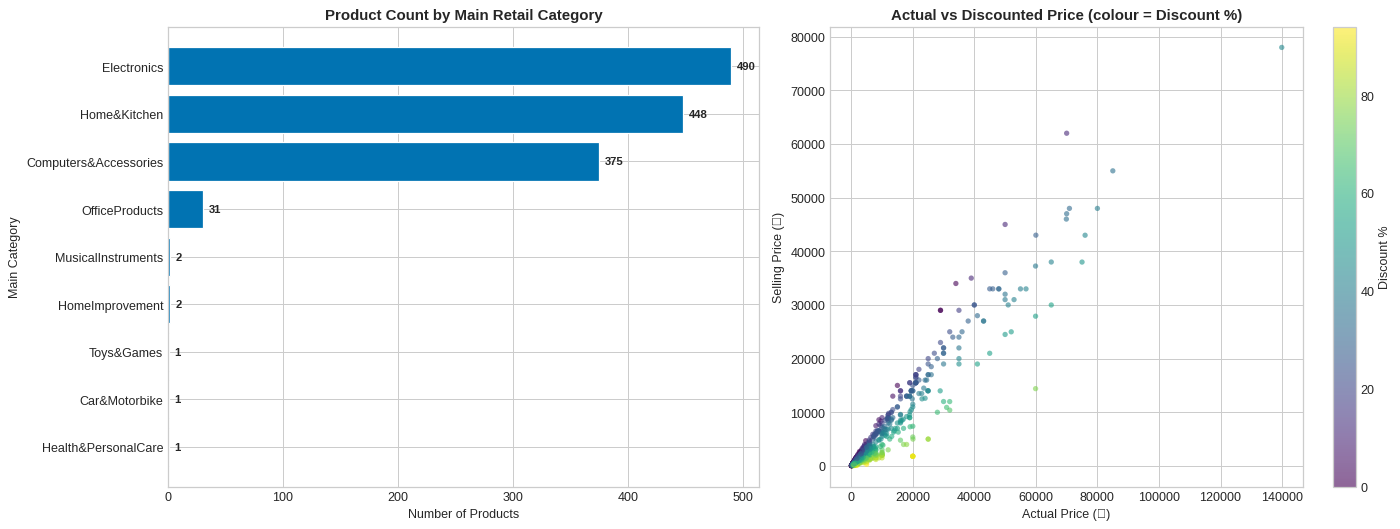

In [8]:
# Category distribution and price relationship
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

cat_counts = df['main_category'].value_counts()
bars = axes[0].barh(cat_counts.index[::-1], cat_counts.values[::-1], color=PALETTE[0], edgecolor='white')
for bar, val in zip(bars, cat_counts.values[::-1]):
    axes[0].text(val + 5, bar.get_y() + bar.get_height() / 2, str(val), va='center', fontsize=9, fontweight='bold')
axes[0].set_title('Product Count by Main Retail Category', fontweight='bold', fontsize=12)
axes[0].set_xlabel('Number of Products')
axes[0].set_ylabel('Main Category')

sc = axes[1].scatter(df['actual_price_clean'], df['discounted_price_clean'],
                     c=df['discount_percentage_clean'], cmap='viridis', alpha=0.6, s=18, edgecolors='none')
plt.colorbar(sc, ax=axes[1], label='Discount %')
axes[1].set_title('Actual vs Discounted Price (colour = Discount %)', fontweight='bold', fontsize=12)
axes[1].set_xlabel('Actual Price (\u20b9)')
axes[1].set_ylabel('Selling Price (\u20b9)')

plt.tight_layout()
plt.savefig('eda_category_colormap.png', dpi=150, bbox_inches='tight')
plt.show()

**Observation (Categories & price):**
About 97% of products fall in three retail categories: Electronics (36.3%), Home & Kitchen (33.2%) and Computers & Accessories (27.8%). The price scatter shows most products below ₹5,000 with a long tail of premium items. The colour (discount %) varies widely at every price level.

### 2b. Price–Discount Relationship by Category

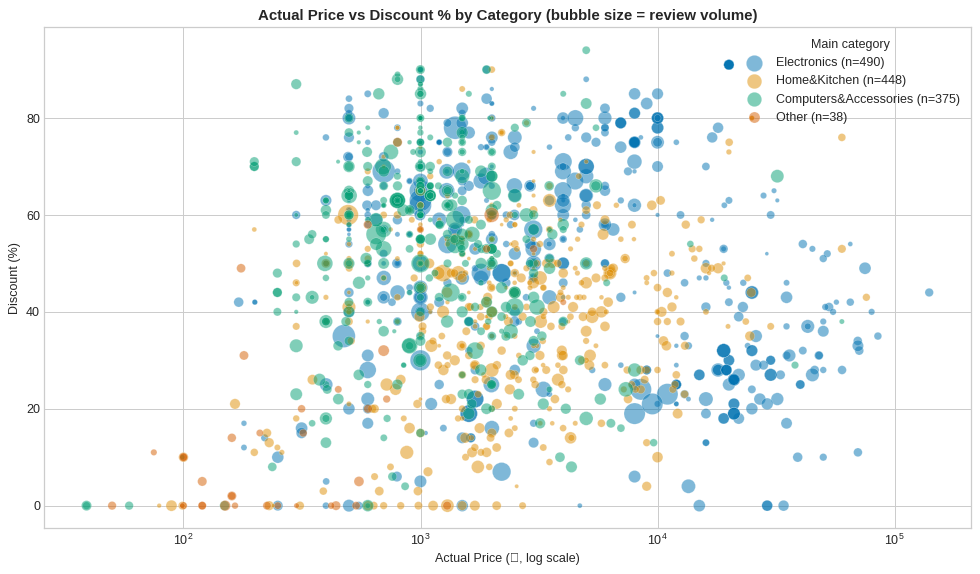

In [9]:
# Static price-discount view by category (bubble size = review volume)
top_cats = df['main_category'].value_counts().index[:3].tolist()
cat_group = df['main_category'].where(df['main_category'].isin(top_cats), 'Other')

fig, ax = plt.subplots(figsize=(11, 6.5))
for i, cat in enumerate(top_cats + ['Other']):
    m = cat_group == cat
    ax.scatter(df.loc[m, 'actual_price_clean'], df.loc[m, 'discount_percentage_clean'],
               s=np.sqrt(df.loc[m, 'rating_count_clean']) / 2 + 8, color=PALETTE[i],
               alpha=0.5, edgecolor='white', linewidth=0.3, label=f'{cat} (n={m.sum()})')
ax.set_xscale('log')
ax.set_title('Actual Price vs Discount % by Category (bubble size = review volume)', fontweight='bold')
ax.set_xlabel('Actual Price (\u20b9, log scale)')
ax.set_ylabel('Discount (%)')
ax.legend(title='Main category', loc='upper right', framealpha=0.9)
plt.tight_layout()
plt.show()

**Observation (Price vs discount):**
Discount depth varies widely at every price level (its correlation with actual price is only −0.11), and the three largest categories overlap heavily on this plot, so neither price nor category determines how deep a discount is. This suggests that segments built from price, discount, rating and engagement together will cut across the retail categories, which Section 9 tests.

## 3. Preprocessing & Feature Engineering

In [10]:
# Feature engineering
# 1. discount_amount: rupee saving (actual - discounted). Used for segment profiling only, not for clustering.
df['discount_amount'] = (df['actual_price_clean'] - df['discounted_price_clean']).clip(lower=0)

# 2. log_rating_count: review counts are extremely right-skewed; log1p compresses the tail
df['log_rating_count'] = np.log1p(df['rating_count_clean'])

# 3. log prices: prices span several orders of magnitude
df['log_actual_price'] = np.log1p(df['actual_price_clean'])
df['log_discounted_price'] = np.log1p(df['discounted_price_clean'])

# Redundancy check between the two log prices
r_price = df['log_actual_price'].corr(df['log_discounted_price'])
print(f"corr(log_actual_price, log_discounted_price) = {r_price:.3f}")
print("Unique main categories:", df['main_category'].nunique())
df[['discount_amount', 'log_rating_count', 'log_actual_price', 'log_discounted_price']].head(3)

corr(log_actual_price, log_discounted_price) = 0.944
Unique main categories: 9


,discount_amount,log_rating_count,log_actual_price,log_discounted_price
0,700.0,10.096996,7.003065,5.991465
1,150.0,10.691831,5.857933,5.298317
2,1700.0,8.978282,7.549609,5.298317


**Feature-engineering justification:**
- `log_rating_count` and the log prices compress the long right tails, so a few extreme products do not dominate the Euclidean distance.
- `discount_amount` (rupee saving) is kept for **profiling segments only**, not for clustering.
- `log_actual_price` and `log_discounted_price` correlate at **0.944**. Using both would count price about twice in every distance calculation, so only `log_actual_price` is kept. The discount % feature already encodes the gap between actual and selling price.

**Final clustering features (4):** `log_actual_price`, `discount_percentage_clean`, `rating_clean`, `log_rating_count`.

In [11]:
# Feature selection and scaling
# log_discounted_price is dropped: it is almost a copy of log_actual_price (r ~ 0.94) and would
# double-count price in the Euclidean distance. The discount % feature already carries the
# actual -> selling price relationship.
features_for_clustering = [
    'log_actual_price',
    'discount_percentage_clean',
    'rating_clean',
    'log_rating_count'
]

# No train/test split exists in clustering (no target, no prediction on unseen data),
# so the scaler is fitted on the full feature matrix. This is not leakage here.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[features_for_clustering])

print("Scaled Feature Matrix Shape:", X_scaled.shape)
print("Feature Means (approx 0):", np.round(X_scaled.mean(axis=0), 3))
print("Feature Stds  (approx 1):", np.round(X_scaled.std(axis=0), 3))

Scaled Feature Matrix Shape: (1351, 4)
Feature Means (approx 0): [ 0.  0. -0.  0.]
Feature Stds  (approx 1): [1. 1. 1. 1.]


## 4. Model 1: K-Means Clustering
K-Means partitions the products into *k* clusters by minimising inertia (within-cluster sum of squares). We search *k* from 2 to 10 and use the elbow curve together with all three validation metrics to pick *k*.

In [12]:
# K-Means search across k in [2, 10]
k_range = range(2, 11)
inertias, silhouette_scores_k, davies_bouldin_scores_k, calinski_harabasz_scores_k = [], [], [], []

print("Running K-Means search (k=2 to 10)...")
for k in k_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    km_labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    silhouette_scores_k.append(silhouette_score(X_scaled, km_labels))
    davies_bouldin_scores_k.append(davies_bouldin_score(X_scaled, km_labels))
    calinski_harabasz_scores_k.append(calinski_harabasz_score(X_scaled, km_labels))
    print(f" - k={k:2d}: Inertia={km.inertia_:9.2f} | Silhouette={silhouette_scores_k[-1]:.4f} | "
          f"DB={davies_bouldin_scores_k[-1]:.4f} | CH={calinski_harabasz_scores_k[-1]:7.2f}")

# Objective elbow: point on the inertia curve farthest from the chord joining its end points
ks = np.array(list(k_range))
pts = np.column_stack([ks, inertias])
p1, p2 = pts[0], pts[-1]
chord_dist = np.abs(np.cross(p2 - p1, pts - p1)) / np.linalg.norm(p2 - p1)
elbow_k = int(ks[chord_dist.argmax()])
print(f"\nChord-distance elbow           : k = {elbow_k}")
print(f"Best silhouette                : k = {ks[int(np.argmax(silhouette_scores_k))]}")
print(f"Best Calinski-Harabasz         : k = {ks[int(np.argmax(calinski_harabasz_scores_k))]}")
print(f"Best Davies-Bouldin (lowest)   : k = {ks[int(np.argmin(davies_bouldin_scores_k))]}")

Running K-Means search (k=2 to 10)...
 - k= 2: Inertia=  4196.74 | Silhouette=0.2178 | DB=1.6901 | CH= 388.08
 - k= 3: Inertia=  3464.94 | Silhouette=0.2149 | DB=1.5010 | CH= 377.19
 - k= 4: Inertia=  2889.85 | Silhouette=0.2343 | DB=1.2947 | CH= 390.63
 - k= 5: Inertia=  2506.61 | Silhouette=0.2368 | DB=1.2694 | CH= 388.96
 - k= 6: Inertia=  2327.37 | Silhouette=0.2265 | DB=1.2834 | CH= 355.60
 - k= 7: Inertia=  2157.92 | Silhouette=0.2216 | DB=1.3003 | CH= 336.96
 - k= 8: Inertia=  2016.02 | Silhouette=0.2202 | DB=1.2732 | CH= 322.43
 - k= 9: Inertia=  1897.89 | Silhouette=0.2073 | DB=1.2879 | CH= 309.90
 - k=10: Inertia=  1796.31 | Silhouette=0.2080 | DB=1.2822 | CH= 299.25

Chord-distance elbow           : k = 5
Best silhouette                : k = 5
Best Calinski-Harabasz         : k = 4
Best Davies-Bouldin (lowest)   : k = 5


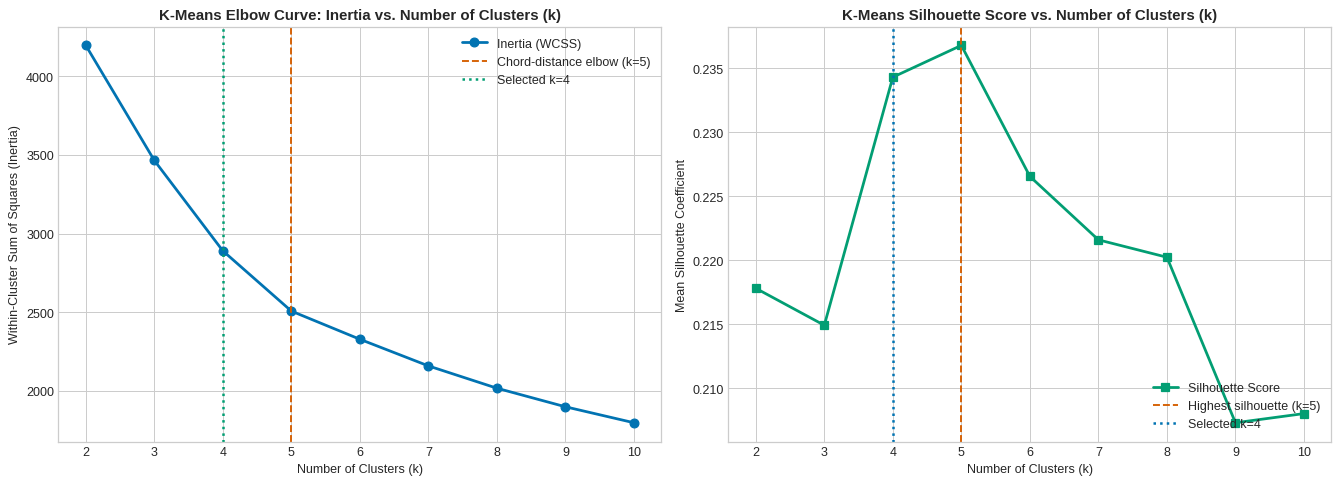

In [13]:
# Elbow curve and silhouette profile
K_PRIMARY, K_ALT = 4, 3     # chosen after inspecting the results above (justified in the next cell)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5))

ax1.plot(k_range, inertias, marker='o', linewidth=2.2, markersize=7, color=PALETTE[0], label='Inertia (WCSS)')
ax1.axvline(x=elbow_k, color=PALETTE[3], linestyle='--', linewidth=1.5, label=f'Chord-distance elbow (k={elbow_k})')
ax1.axvline(x=K_PRIMARY, color=PALETTE[2], linestyle=':', linewidth=2, label=f'Selected k={K_PRIMARY}')
ax1.set_title("K-Means Elbow Curve: Inertia vs. Number of Clusters (k)", fontsize=12, fontweight='bold')
ax1.set_xlabel("Number of Clusters (k)")
ax1.set_ylabel("Within-Cluster Sum of Squares (Inertia)")
ax1.set_xticks(list(k_range))
ax1.legend(loc='upper right')

ax2.plot(k_range, silhouette_scores_k, marker='s', linewidth=2.2, markersize=7, color=PALETTE[2], label='Silhouette Score')
best_sil_k = int(ks[int(np.argmax(silhouette_scores_k))])
ax2.axvline(x=best_sil_k, color=PALETTE[3], linestyle='--', linewidth=1.5, label=f'Highest silhouette (k={best_sil_k})')
ax2.axvline(x=K_PRIMARY, color=PALETTE[0], linestyle=':', linewidth=2, label=f'Selected k={K_PRIMARY}')
ax2.set_title("K-Means Silhouette Score vs. Number of Clusters (k)", fontsize=12, fontweight='bold')
ax2.set_xlabel("Number of Clusters (k)")
ax2.set_ylabel("Mean Silhouette Coefficient")
ax2.set_xticks(list(k_range))
ax2.legend(loc='lower right')

plt.tight_layout()
plt.show()

**Observation (Choosing k):**
- Inertia falls smoothly with no sharp bend. The objective chord-distance method points to k = 5.
- The silhouette is 0.218 at k = 2, dips to 0.215 at k = 3, and peaks at k = 5 (0.2368), with k = 4 almost equal (0.2343).
- Calinski-Harabasz peaks at **k = 4** (390.6). Davies-Bouldin is lowest at k = 5 (1.269), with k = 4 close behind (1.295).

k = 4 and k = 5 are nearly tied. We select **k = 4**: it has the best Calinski-Harabasz score, is within 0.003 of the best silhouette, gives four distinct, interpretable segments, and is the cut supported by the dendrogram (Section 5). k = 3 is **not** supported by the metrics (its silhouette is lower than both k = 2 and k = 4), so it is kept only as a comparison model.

In [14]:
# Fit the selected model (k=4) and the alternative (k=3)
kmeans_primary = KMeans(n_clusters=K_PRIMARY, random_state=RANDOM_STATE, n_init=10).fit(X_scaled)
labels_km4 = kmeans_primary.labels_
kmeans_alt = KMeans(n_clusters=K_ALT, random_state=RANDOM_STATE, n_init=10).fit(X_scaled)
labels_km3 = kmeans_alt.labels_

for name, lab in [('K-Means (k=4)', labels_km4), ('K-Means (k=3)', labels_km3)]:
    print(f"\nCluster membership for {name}:")
    for c, count in enumerate(np.bincount(lab)):
        print(f" - Cluster {c}: {count} products ({count / len(X_scaled) * 100:.1f}%)")


Cluster membership for K-Means (k=4):
 - Cluster 0: 300 products (22.2%)
 - Cluster 1: 338 products (25.0%)
 - Cluster 2: 447 products (33.1%)
 - Cluster 3: 266 products (19.7%)

Cluster membership for K-Means (k=3):
 - Cluster 0: 565 products (41.8%)
 - Cluster 1: 368 products (27.2%)
 - Cluster 2: 418 products (30.9%)


## 5. Model 2: Agglomerative Hierarchical Clustering
Builds a merge tree bottom-up. Ward linkage merges the pair of clusters that increases total within-cluster variance the least. The dendrogram cut heights below are computed from the linkage matrix and verified, not typed in by hand.

Cut height for k=4: 30.59 | Cut height for k=3: 36.24
Last merge heights (2->1, 3->2, 4->3, 5->4 clusters): [43.67 37.29 35.19 26.  ]


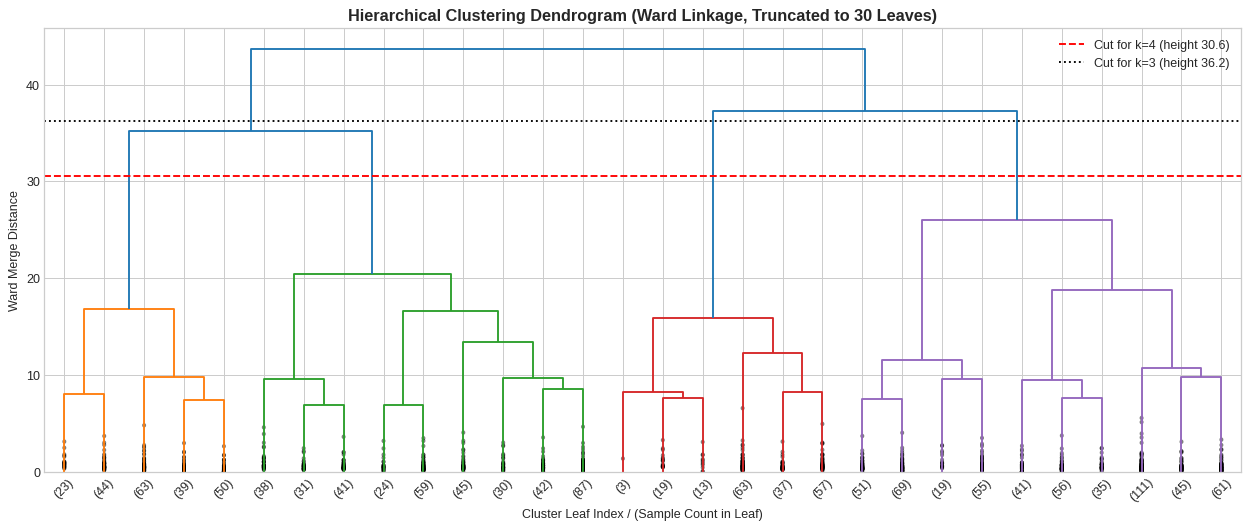

In [15]:
# Ward linkage matrix and dendrogram
linkage_ward = linkage(X_scaled, method='ward')

def cut_height(Z, k):
    """Distance threshold that yields exactly k clusters: midpoint of the gap between merge k and k-1."""
    return (Z[-k, 2] + Z[-(k - 1), 2]) / 2

cut_k4, cut_k3 = cut_height(linkage_ward, 4), cut_height(linkage_ward, 3)
# Verify that the thresholds really give the cluster counts we claim
assert len(np.unique(fcluster(linkage_ward, cut_k4, criterion='distance'))) == 4
assert len(np.unique(fcluster(linkage_ward, cut_k3, criterion='distance'))) == 3
print(f"Cut height for k=4: {cut_k4:.2f} | Cut height for k=3: {cut_k3:.2f}")
print("Last merge heights (2->1, 3->2, 4->3, 5->4 clusters):", np.round(linkage_ward[-1:-5:-1, 2], 2))

plt.figure(figsize=(14, 6))
dendrogram(linkage_ward, truncate_mode='lastp', p=30, leaf_rotation=45., leaf_font_size=10.,
           show_contracted=True, color_threshold=cut_k4)
plt.axhline(y=cut_k4, color='red', linestyle='--', linewidth=1.5, label=f'Cut for k=4 (height {cut_k4:.1f})')
plt.axhline(y=cut_k3, color='black', linestyle=':', linewidth=1.5, label=f'Cut for k=3 (height {cut_k3:.1f})')
plt.title("Hierarchical Clustering Dendrogram (Ward Linkage, Truncated to 30 Leaves)", fontsize=13, fontweight='bold')
plt.xlabel("Cluster Leaf Index / (Sample Count in Leaf)")
plt.ylabel("Ward Merge Distance")
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

**Observation (Dendrogram):**
The last merges happen at heights 26.0 (5→4 clusters), 35.2 (4→3), 37.3 (3→2) and 43.7 (2→1). The largest jump among these is between 26.0 and 35.2, so cutting just before the 4→3 merge (height ≈ 30.6) is the most natural choice, which agrees with k = 4 from K-Means. The 4→3 and 3→2 merges are close together (35.2 vs 37.3), so the tree gives no strong reason to prefer k = 3. The assertions in the code confirm that the two drawn cut lines produce exactly 4 and 3 clusters.

In [16]:
# Agglomerative models: three linkages at k=4, plus Ward at k=3 for comparison with K-Means (k=3)
agg_labels = {}
for method in ['ward', 'complete', 'average']:
    agg_labels[method] = AgglomerativeClustering(n_clusters=K_PRIMARY, linkage=method).fit_predict(X_scaled)
    print(f"Agglomerative linkage='{method}' (k={K_PRIMARY}): cluster sizes = {np.bincount(agg_labels[method]).tolist()}")

labels_ward3 = AgglomerativeClustering(n_clusters=K_ALT, linkage='ward').fit_predict(X_scaled)
print(f"Agglomerative linkage='ward' (k={K_ALT}): cluster sizes = {np.bincount(labels_ward3).tolist()}")

Agglomerative linkage='ward' (k=4): cluster sizes = [543, 397, 192, 219]
Agglomerative linkage='complete' (k=4): cluster sizes = [1179, 65, 100, 7]
Agglomerative linkage='average' (k=4): cluster sizes = [1342, 7, 1, 1]
Agglomerative linkage='ward' (k=3): cluster sizes = [616, 543, 192]


**Observation (Linkage comparison):**
Ward gives balanced clusters (543, 397, 192, 219). Complete linkage (1179, 65, 100, 7) and Average linkage (1342, 7, 1, 1) produce degenerate partitions dominated by one huge cluster plus tiny ones, because these linkages are sensitive to the extreme-price and extreme-review outliers. They are reported for completeness, but **Ward is the only linkage that gives a usable segmentation**.

## 6. Cluster Validation & Evaluation
All three mandatory metrics are computed for every configuration on the same scaled feature matrix: **Silhouette** (higher is better), **Davies-Bouldin** (lower is better) and **Calinski-Harabasz** (higher is better).

In [17]:
# Validation metrics for every configuration
models_to_evaluate = {
    'K-Means (k=3)': labels_km3,
    'K-Means (k=4)': labels_km4,
    'Agglomerative (Ward, k=3)': labels_ward3,
    'Agglomerative (Ward, k=4)': agg_labels['ward'],
    'Agglomerative (Complete, k=4)': agg_labels['complete'],
    'Agglomerative (Average, k=4)': agg_labels['average'],
}

records = []
for model_name, labels in models_to_evaluate.items():
    records.append({
        'Algorithm / Configuration': model_name,
        'Clusters (k)': len(np.unique(labels)),
        'Smallest cluster': int(np.bincount(labels).min()),
        'Silhouette Score (\u2191)': silhouette_score(X_scaled, labels),
        'Davies-Bouldin Index (\u2193)': davies_bouldin_score(X_scaled, labels),
        'Calinski-Harabasz Index (\u2191)': calinski_harabasz_score(X_scaled, labels),
    })
comparison_df = pd.DataFrame(records).set_index('Algorithm / Configuration')

(comparison_df.style
    .format({'Silhouette Score (\u2191)': '{:.4f}', 'Davies-Bouldin Index (\u2193)': '{:.4f}',
             'Calinski-Harabasz Index (\u2191)': '{:.2f}'})
    .highlight_max(subset=['Silhouette Score (\u2191)', 'Calinski-Harabasz Index (\u2191)'], color='#d4edda')
    .highlight_min(subset=['Davies-Bouldin Index (\u2193)'], color='#d4edda'))

,Clusters (k),Smallest cluster,Silhouette Score (↑),Davies-Bouldin Index (↓),Calinski-Harabasz Index (↑)
Algorithm / Configuration,,,,,
K-Means (k=3),3,368,0.2149,1.5010,377.19
K-Means (k=4),4,266,0.2343,1.2947,390.63
"Agglomerative (Ward, k=3)",3,192,0.1716,1.7163,295.86
"Agglomerative (Ward, k=4)",4,192,0.1942,1.4852,324.62
"Agglomerative (Complete, k=4)",4,7,0.1585,1.4615,102.25
"Agglomerative (Average, k=4)",4,1,0.3628,0.5144,22.37


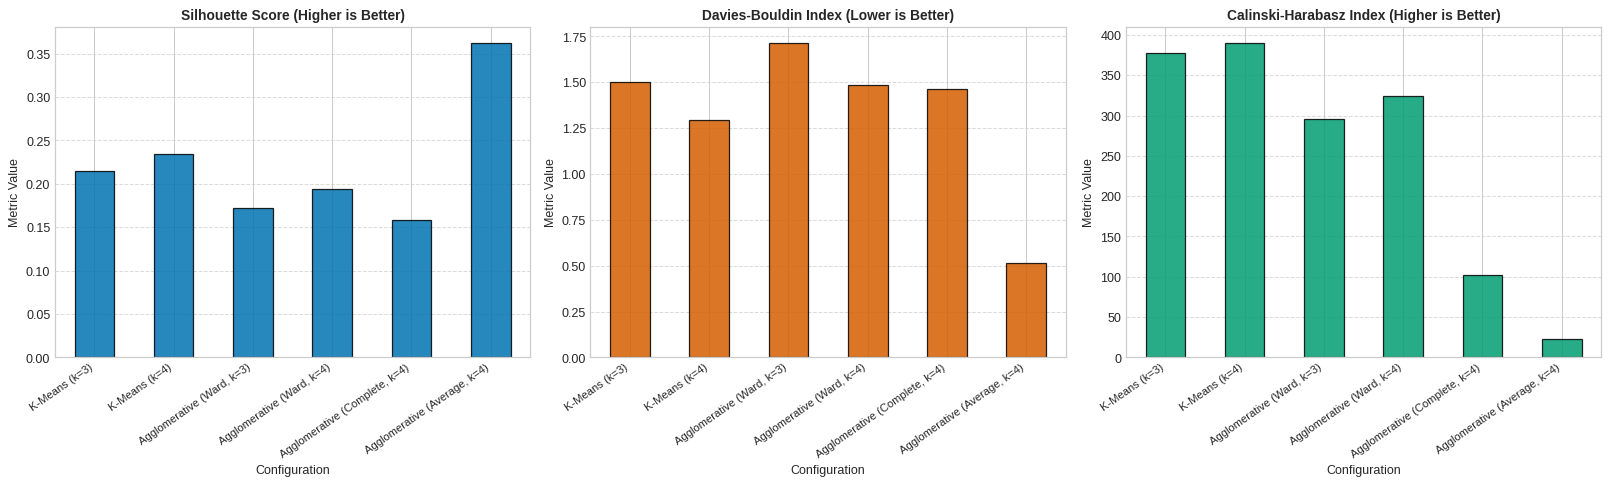

In [18]:
# Comparative bar charts
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
metric_specs = [
    ('Silhouette Score (\u2191)', 'Silhouette Score (Higher is Better)', PALETTE[0]),
    ('Davies-Bouldin Index (\u2193)', 'Davies-Bouldin Index (Lower is Better)', PALETTE[3]),
    ('Calinski-Harabasz Index (\u2191)', 'Calinski-Harabasz Index (Higher is Better)', PALETTE[2]),
]
for ax, (col, title_label, color) in zip(axes, metric_specs):
    comparison_df[col].plot(kind='bar', ax=ax, color=color, edgecolor='black', alpha=0.85)
    ax.set_title(title_label, fontsize=11, fontweight='bold')
    ax.set_ylabel("Metric Value")
    ax.set_xlabel("Configuration")
    ax.set_xticklabels(comparison_df.index, rotation=35, ha='right', fontsize=9)
    ax.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

**Observation (Metrics):**
K-Means (k=4) has the best Calinski-Harabasz (390.6) among the balanced partitions, and K-Means beats Ward on all three metrics at both k = 3 and k = 4. The Average-linkage row (silhouette 0.363, Davies-Bouldin 0.514) looks like the best result, but it contains a single-product cluster and a 7-product cluster. These scores come from that degenerate split, and its Calinski-Harabasz of 22.4 is the lowest of all. We therefore do not treat it as a real winner (see Section 7). All silhouette values are below 0.25, which is generally read as **weak cluster structure**: the segments are tendencies in a continuous product space rather than sharply separated groups.

## 7. Best Model Comparison
Summarises the evaluation and selects the best model as the guidelines require (Review 2 criterion A3/B2: best model identified with clear justification). Each valid configuration is ranked on the three metrics and the ranks are averaged. A partition with any cluster below 2% of the products is treated as degenerate and excluded, so the near-empty Complete and Average clusterings cannot win through a metric artefact. A second table compares K-Means and Ward at the same k, since all three metrics depend on k.

In [19]:
# Best-model comparison: rank every configuration on all three validation metrics
MIN_SHARE = 0.02    # a partition with a cluster smaller than 2% of the products is treated as degenerate
n_total = len(X_scaled)

cmp = comparison_df.copy()
cmp['Valid partition'] = cmp['Smallest cluster'] >= MIN_SHARE * n_total

ranks = pd.DataFrame(index=cmp.index)
valid = cmp[cmp['Valid partition']]
ranks['Silhouette rank'] = valid['Silhouette Score (\u2191)'].rank(ascending=False)
ranks['Davies-Bouldin rank'] = valid['Davies-Bouldin Index (\u2193)'].rank(ascending=True)
ranks['Calinski-Harabasz rank'] = valid['Calinski-Harabasz Index (\u2191)'].rank(ascending=False)
ranks['Mean rank (lower = better)'] = ranks.mean(axis=1)

best_table = cmp.join(ranks).sort_values('Mean rank (lower = better)')
best_model_name = best_table.index[0]
print(f"Best overall configuration (lowest mean rank among valid partitions): {best_model_name}")
print(f"Degenerate partitions excluded from ranking: {cmp.index[~cmp['Valid partition']].tolist()}")

(best_table.style
    .format({'Silhouette Score (\u2191)': '{:.4f}', 'Davies-Bouldin Index (\u2193)': '{:.4f}',
             'Calinski-Harabasz Index (\u2191)': '{:.2f}', 'Silhouette rank': '{:.0f}',
             'Davies-Bouldin rank': '{:.0f}', 'Calinski-Harabasz rank': '{:.0f}',
             'Mean rank (lower = better)': '{:.2f}'}, na_rep='excluded')
    .highlight_min(subset=['Mean rank (lower = better)'], color='#d4edda'))

Best overall configuration (lowest mean rank among valid partitions): K-Means (k=4)
Degenerate partitions excluded from ranking: ['Agglomerative (Complete, k=4)', 'Agglomerative (Average, k=4)']


,Clusters (k),Smallest cluster,Silhouette Score (↑),Davies-Bouldin Index (↓),Calinski-Harabasz Index (↑),Valid partition,Silhouette rank,Davies-Bouldin rank,Calinski-Harabasz rank,Mean rank (lower = better)
Algorithm / Configuration,,,,,,,,,,
K-Means (k=4),4,266,0.2343,1.2947,390.63,True,1,1,1,1.00
K-Means (k=3),3,368,0.2149,1.5010,377.19,True,2,3,2,2.33
"Agglomerative (Ward, k=4)",4,192,0.1942,1.4852,324.62,True,3,2,3,2.67
"Agglomerative (Ward, k=3)",3,192,0.1716,1.7163,295.86,True,4,4,4,4.00
"Agglomerative (Complete, k=4)",4,7,0.1585,1.4615,102.25,False,excluded,excluded,excluded,excluded
"Agglomerative (Average, k=4)",4,1,0.3628,0.5144,22.37,False,excluded,excluded,excluded,excluded


K-Means vs Agglomerative (Ward) head-to-head:
                                K-Means  Agglomerative (Ward)         Winner
k Metric                                                                    
3 Silhouette Score (↑)           0.2149                0.1716  K-Means (k=3)
  Davies-Bouldin Index (↓)       1.5010                1.7163  K-Means (k=3)
  Calinski-Harabasz Index (↑)  377.1862              295.8648  K-Means (k=3)
4 Silhouette Score (↑)           0.2343                0.1942  K-Means (k=4)
  Davies-Bouldin Index (↓)       1.2947                1.4852  K-Means (k=4)
  Calinski-Harabasz Index (↑)  390.6322              324.6152  K-Means (k=4)


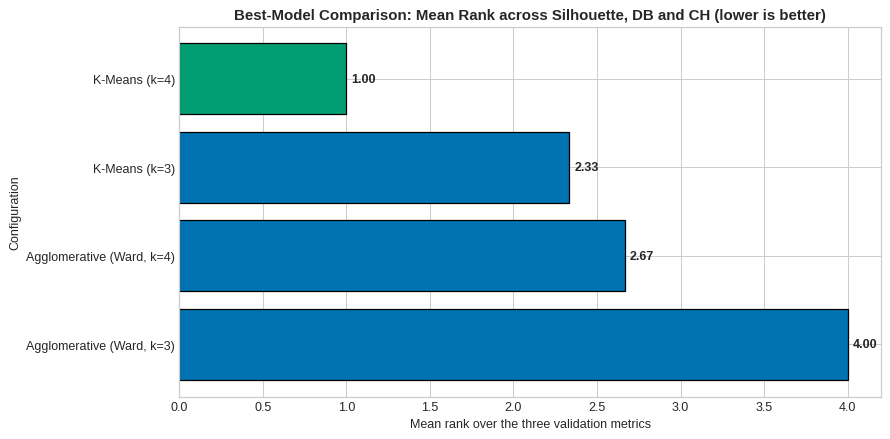

In [20]:
# Like-for-like comparison: K-Means vs Hierarchical at the SAME k (a fair test, since the metrics depend on k)
rows = []
for k_val in (3, 4):
    km_name = f'K-Means (k={k_val})'
    ag_name = f'Agglomerative (Ward, k={k_val})'
    for metric, better in [('Silhouette Score (\u2191)', 'max'), ('Davies-Bouldin Index (\u2193)', 'min'),
                           ('Calinski-Harabasz Index (\u2191)', 'max')]:
        a, b = comparison_df.loc[km_name, metric], comparison_df.loc[ag_name, metric]
        win = km_name if ((a > b) if better == 'max' else (a < b)) else ag_name
        rows.append({'k': k_val, 'Metric': metric, 'K-Means': a, 'Agglomerative (Ward)': b, 'Winner': win})
head_to_head = pd.DataFrame(rows).set_index(['k', 'Metric'])
print("K-Means vs Agglomerative (Ward) head-to-head:")
print(head_to_head.round(4).to_string())

# Visual: mean rank per valid configuration
fig, ax = plt.subplots(figsize=(10, 5))
plot_df = best_table.dropna(subset=['Mean rank (lower = better)']).sort_values('Mean rank (lower = better)', ascending=False)
bar_colors = [PALETTE[2] if n == best_model_name else PALETTE[0] for n in plot_df.index]
ax.barh(plot_df.index, plot_df['Mean rank (lower = better)'], color=bar_colors, edgecolor='black')
for y, v in enumerate(plot_df['Mean rank (lower = better)']):
    ax.text(v + 0.03, y, f'{v:.2f}', va='center', fontweight='bold')
ax.set_title('Best-Model Comparison: Mean Rank across Silhouette, DB and CH (lower is better)', fontweight='bold', fontsize=12)
ax.set_xlabel('Mean rank over the three validation metrics')
ax.set_ylabel('Configuration')
plt.tight_layout()
plt.show()

**Observation (Best model):**
**K-Means (k=4) is the best model.** It ranks first on all three metrics (mean rank 1.00), ahead of K-Means (k=3) at 2.33, Ward (k=4) at 2.67 and Ward (k=3) at 4.00. In the like-for-like table K-Means wins every one of the six metric comparisons against Ward (for example at k=4: silhouette 0.234 vs 0.194, Davies-Bouldin 1.295 vs 1.485, Calinski-Harabasz 390.6 vs 324.6). This is consistent with the t-SNE view in Section 8, where Ward's clusters 0 and 2 interleave while K-Means gives more compact regions.

**Trade-offs and caveats:**
- The metrics themselves reward compact, roughly spherical clusters, which is exactly what K-Means optimises, so they favour K-Means somewhat by construction.
- Hierarchical clustering still adds value: the dendrogram independently supports k = 4 and shows the nesting of segments, and it needs no random initialisation.
- Absolute scores are low (silhouette 0.234), so conclusions about segments should be stated cautiously.

K-Means (k=4) is therefore used for the segment analysis in Sections 9–11.

## 8. Cluster Visualisation (PCA & t-SNE)
PCA preserves global variance and is mandatory for every configuration; t-SNE preserves local neighbourhoods and is shown for the two main models.

In [21]:
# 2D projections: PCA (global variance) and t-SNE (local neighbourhoods)
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)
evr = pca.explained_variance_ratio_
print("PCA fitted:")
print(f" - PC1: {evr[0]*100:.2f}% | PC2: {evr[1]*100:.2f}% | cumulative: {evr.sum()*100:.2f}%")

print("\nFitting t-SNE (perplexity=30)...")
tsne = TSNE(n_components=2, random_state=RANDOM_STATE, perplexity=30)
X_tsne = tsne.fit_transform(X_scaled)
print("t-SNE projection completed.")

PCA fitted:
 - PC1: 34.82% | PC2: 24.87% | cumulative: 59.69%

Fitting t-SNE (perplexity=30)...
t-SNE projection completed.


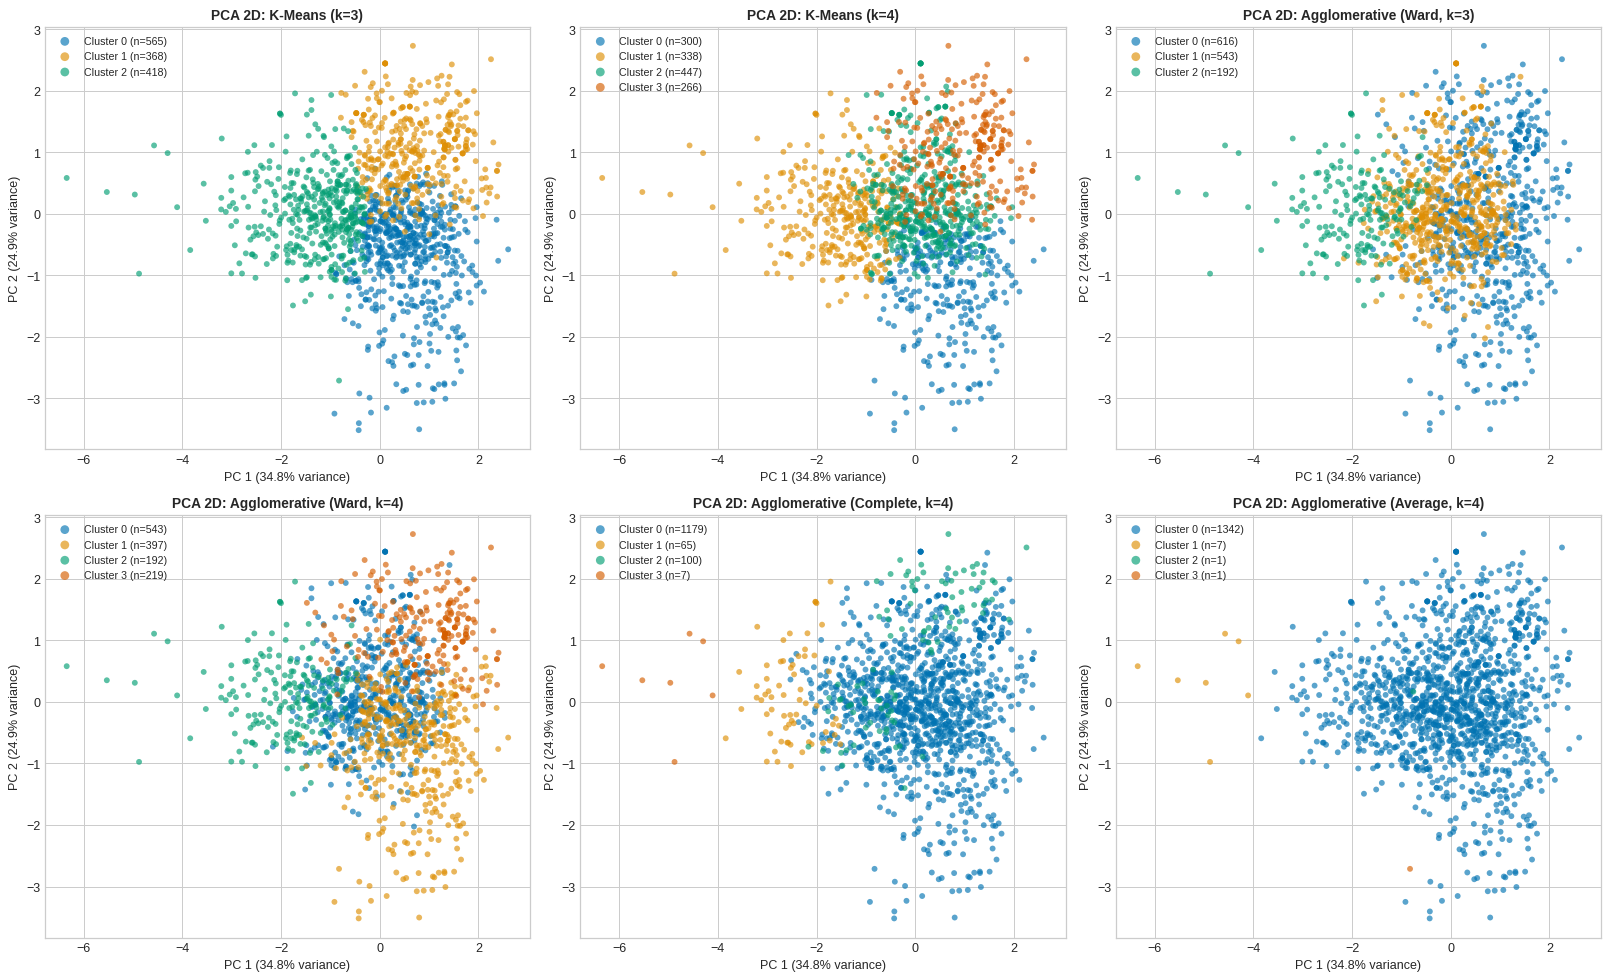

In [22]:
# PCA 2D scatter for EVERY clustering configuration
plot_configs = list(models_to_evaluate.items())
fig, axes = plt.subplots(2, 3, figsize=(18, 11))

for ax, (title, labels) in zip(axes.flatten(), plot_configs):
    for l_idx, label_val in enumerate(np.unique(labels)):
        mask = labels == label_val
        ax.scatter(X_pca[mask, 0], X_pca[mask, 1], color=PALETTE[l_idx % len(PALETTE)],
                   label=f'Cluster {label_val} (n={mask.sum()})', alpha=0.65, edgecolor='none', s=22)
    ax.set_title(f"PCA 2D: {title}", fontsize=11, fontweight='bold')
    ax.set_xlabel(f"PC 1 ({evr[0]*100:.1f}% variance)")
    ax.set_ylabel(f"PC 2 ({evr[1]*100:.1f}% variance)")
    ax.legend(loc='best', fontsize=8.5, markerscale=1.5)
plt.tight_layout()
plt.show()

**Observation (PCA):**
The two components explain 34.8% + 24.9% = **59.7%** of the variance, so about 40% of the structure is not visible in 2D and some overlap between clusters is expected. K-Means (k=4) and Ward (k=4) show visible regional structure with clear overlap at the boundaries, consistent with the weak silhouette. The Complete and Average panels show one dominant cluster with a few tiny groups (the degenerate partitions from Section 5).

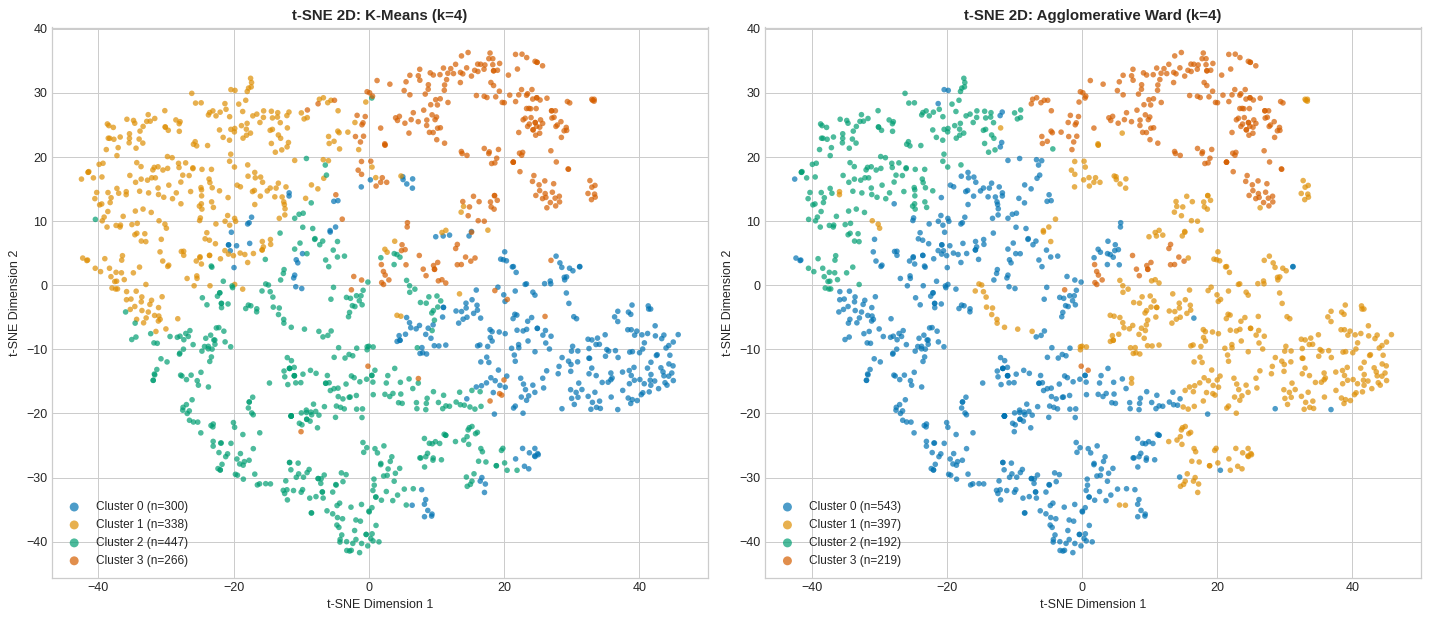

In [23]:
# t-SNE 2D scatter for the two selected models
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, (title, labels) in zip(axes, [('K-Means (k=4)', labels_km4), ('Agglomerative Ward (k=4)', agg_labels['ward'])]):
    for l_idx, label_val in enumerate(np.unique(labels)):
        mask = labels == label_val
        ax.scatter(X_tsne[mask, 0], X_tsne[mask, 1], color=PALETTE[l_idx % len(PALETTE)],
                   label=f'Cluster {label_val} (n={mask.sum()})', alpha=0.7, edgecolor='none', s=20)
    ax.set_title(f"t-SNE 2D: {title}", fontsize=12, fontweight='bold')
    ax.set_xlabel("t-SNE Dimension 1")
    ax.set_ylabel("t-SNE Dimension 2")
    ax.legend(loc='best', fontsize=9.5, markerscale=1.6)
plt.tight_layout()
plt.show()

**Observation (t-SNE):**
For K-Means (k=4) the four clusters occupy mostly contiguous regions of the map, touching at their borders rather than forming isolated islands. For Ward (k=4) clusters 0 and 2 are heavily interleaved in the left half, which matches Ward's lower scores. t-SNE distances between far-apart groups are not meaningful, so this is used only as a check on local cohesion.

### 8a. PCA Biplot — Feature Projection Vectors on Cluster Scatter

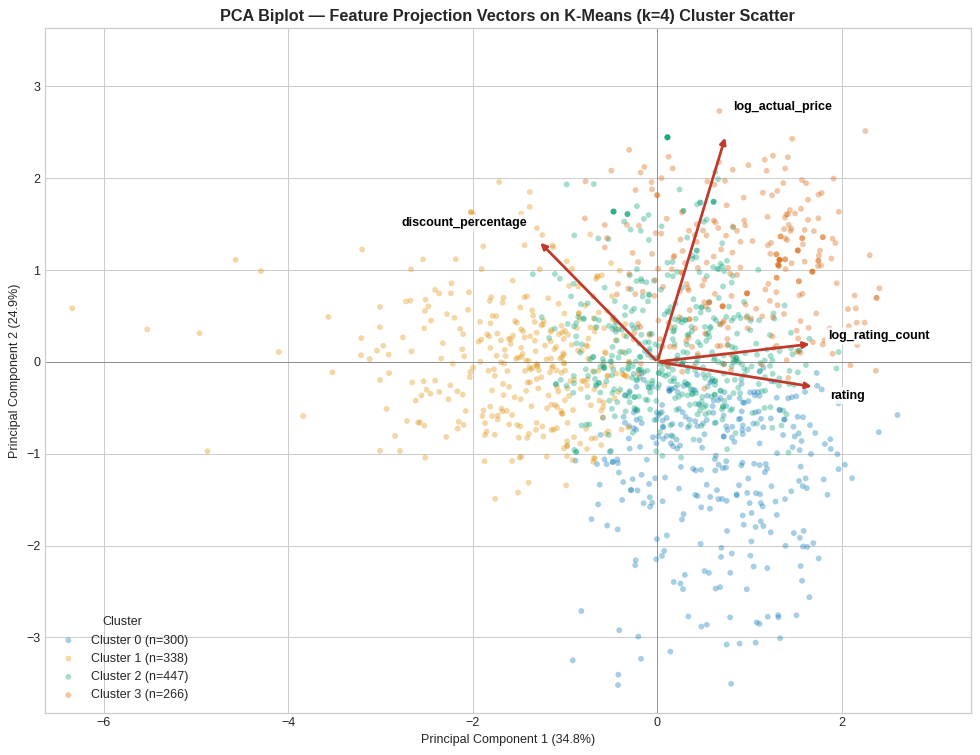

,PC1 loading,PC2 loading
log_actual_price,0.264,0.876
discount_percentage,-0.457,0.467
rating,0.605,-0.097
log_rating_count,0.596,0.069


In [24]:
# PCA biplot: feature loading vectors drawn over the K-Means (k=4) cluster scatter
pretty_feat = ['log_actual_price', 'discount_percentage', 'rating', 'log_rating_count']
loadings = pca.components_.T                      # shape (n_features, 2)
arrow_scale = 0.8 * min(np.abs(X_pca[:, 0]).max(), np.abs(X_pca[:, 1]).max())   # stretch unit loadings to the plot range

fig, ax = plt.subplots(figsize=(11, 8.5))
for l_idx, label_val in enumerate(np.unique(labels_km4)):
    mask = labels_km4 == label_val
    ax.scatter(X_pca[mask, 0], X_pca[mask, 1], color=PALETTE[l_idx], alpha=0.35, s=22,
               edgecolor='none', label=f'Cluster {label_val} (n={mask.sum()})')

for i, name in enumerate(pretty_feat):
    dx, dy = loadings[i, 0] * arrow_scale, loadings[i, 1] * arrow_scale
    ax.annotate('', xy=(dx, dy), xytext=(0, 0),
                arrowprops=dict(arrowstyle='-|>', color='#c0392b', lw=2.2))
    ax.text(dx * 1.1, dy * 1.1, name, color='black', fontsize=10, fontweight='bold',
            ha='left' if dx >= 0 else 'right', va='bottom' if dy >= 0 else 'top',
            bbox=dict(boxstyle='round,pad=0.2', fc='white', ec='none', alpha=0.8))

# make sure arrows and their labels stay inside the axes
tips = loadings * arrow_scale * 1.35
ax.set_xlim(min(X_pca[:, 0].min(), tips[:, 0].min()) - 0.3, max(X_pca[:, 0].max(), tips[:, 0].max()) + 0.8)
ax.set_ylim(min(X_pca[:, 1].min(), tips[:, 1].min()) - 0.3, max(X_pca[:, 1].max(), tips[:, 1].max()) + 0.3)
ax.axhline(0, color='grey', linewidth=0.6)
ax.axvline(0, color='grey', linewidth=0.6)
ax.set_title('PCA Biplot \u2014 Feature Projection Vectors on K-Means (k=4) Cluster Scatter', fontweight='bold', fontsize=13)
ax.set_xlabel(f'Principal Component 1 ({evr[0]*100:.1f}%)')
ax.set_ylabel(f'Principal Component 2 ({evr[1]*100:.1f}%)')
ax.legend(title='Cluster', loc='lower left', framealpha=0.9)
plt.tight_layout()
plt.savefig('pca_biplot_feature_loadings.png', dpi=150, bbox_inches='tight')
plt.show()

pd.DataFrame(pca.components_.T, index=pretty_feat, columns=['PC1 loading', 'PC2 loading']).round(3)

**Observation (Biplot):**
This biplot is computed from the same PCA as the scatter plots above (explained variance 34.8% / 24.9%), using the four clustering features. PC1 mainly separates **engagement and quality** (`rating` 0.61, `log_rating_count` 0.60) from **discount depth** (−0.46). PC2 is mainly **price** (`log_actual_price` 0.88) with some discount (0.47). The left-hand cluster 1 lies along the discount arrow (heavily discounted, less-reviewed products), the upper-right cluster 3 lies along the price arrow (premium products), and cluster 0 sits at the bottom, the opposite side from both price and discount. Rating and review count point the same way, so they move together across segments.

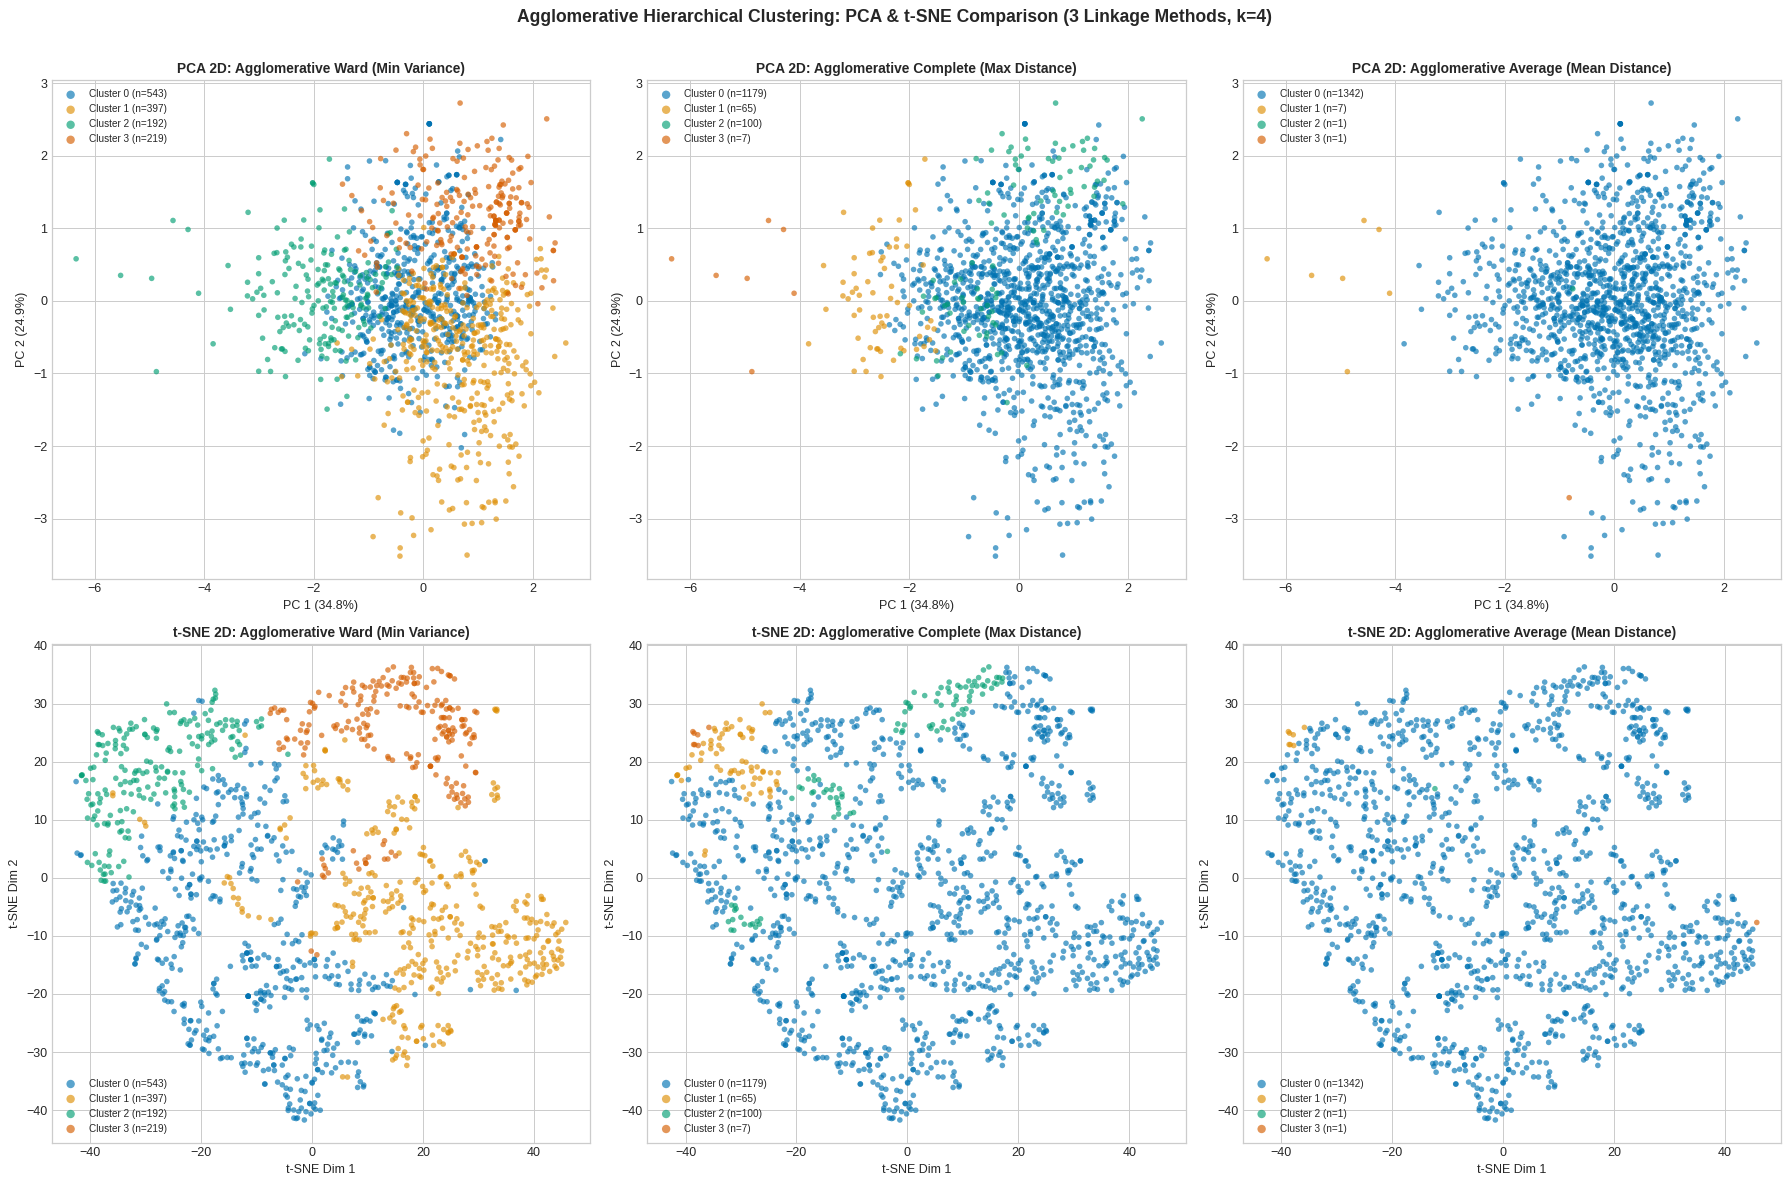

In [25]:
# Agglomerative linkage comparison (k=4): PCA (top row) and t-SNE (bottom row)
linkage_names = ['ward', 'complete', 'average']
link_titles = ['Ward (Min Variance)', 'Complete (Max Distance)', 'Average (Mean Distance)']

fig, axes = plt.subplots(2, 3, figsize=(20, 13))
for j, (method, title) in enumerate(zip(linkage_names, link_titles)):
    lbls = agg_labels[method]
    for row, (emb, xl, yl, tag) in enumerate([
            (X_pca, f'PC 1 ({evr[0]*100:.1f}%)', f'PC 2 ({evr[1]*100:.1f}%)', 'PCA 2D'),
            (X_tsne, 't-SNE Dim 1', 't-SNE Dim 2', 't-SNE 2D')]):
        ax = axes[row, j]
        for k in np.unique(lbls):
            mask = lbls == k
            ax.scatter(emb[mask, 0], emb[mask, 1], color=PALETTE[k % len(PALETTE)],
                       label=f'Cluster {k} (n={mask.sum()})', alpha=0.65, s=20, edgecolor='none')
        ax.set_title(f'{tag}: Agglomerative {title}', fontsize=11, fontweight='bold')
        ax.set_xlabel(xl)
        ax.set_ylabel(yl)
        ax.legend(fontsize=8, markerscale=1.5, framealpha=0.8)
fig.suptitle('Agglomerative Hierarchical Clustering: PCA & t-SNE Comparison (3 Linkage Methods, k=4)',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('agglomerative_pca_tsne_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

**Observation (Linkage comparison plots):**
Ward is the only linkage that splits the plane into four substantial groups. Complete and Average linkage leave almost all points in one cluster and isolate a handful of outliers, as expected from their cluster sizes.

## 9. Market Segment Interpretation (Post-hoc Validation, Guidelines §3.3)
Cluster medians are shown in original units to describe each segment. Segment names are assigned by rules on the medians, so they stay correct even if the cluster numbering changes. Retail categories are used here for the first time, only to validate the result.

In [26]:
# Segment profiles on the original (unscaled) units for K-Means (k=4)
df_analyzed = df.copy()
df_analyzed['Cluster'] = labels_km4

profile_features = ['discounted_price_clean', 'actual_price_clean', 'discount_percentage_clean',
                    'discount_amount', 'rating_clean', 'rating_count_clean']
prof = df_analyzed.groupby('Cluster')[profile_features].median()
prof['Product_Count'] = df_analyzed.groupby('Cluster').size()
prof['Population_%'] = prof['Product_Count'] / len(df_analyzed) * 100

# Segment names are derived from the medians (not hard-coded), so they stay correct if labels change
def name_segments(p):
    names, remaining = {}, set(p.index)
    premium = p.loc[list(remaining), 'actual_price_clean'].idxmax()
    names[premium] = 'Premium Tech & Appliances'; remaining.discard(premium)
    low_eng = p.loc[list(remaining), 'rating_count_clean'].idxmin()
    names[low_eng] = 'Deep-Discount, Low-Engagement Items'; remaining.discard(low_eng)
    low_disc = p.loc[list(remaining), 'discount_percentage_clean'].idxmin()
    names[low_disc] = 'Low-Discount Steady Sellers'; remaining.discard(low_disc)
    names[remaining.pop()] = 'High-Volume Value Staples'
    return names

seg_names = name_segments(prof)
seg_short = {c: n.replace(', ', ',\n').replace(' & ', ' &\n') if len(n) > 22 else n for c, n in seg_names.items()}
seg_color = {c: PALETTE[i] for i, c in enumerate(sorted(seg_names))}

prof.insert(0, 'Market Segment', prof.index.map(seg_names))
prof.columns = ['Market Segment', 'Selling Price (\u20b9)', 'Actual Price (\u20b9)', 'Discount %',
                'Cash Savings (\u20b9)', 'Rating (1-5)', 'Review Count', 'Product Count', 'Population %']
prof.round(2)

,Market Segment,Selling Price (₹),Actual Price (₹),Discount %,Cash Savings (₹),Rating (1-5),Review Count,Product Count,Population %
Cluster,,,,,,,,,
0,Low-Discount Steady Sellers,651.0,899.5,22.0,200.0,4.2,6534.0,300,22.21
1,"Deep-Discount, Low-Engagement Items",471.5,1292.5,58.0,800.0,3.9,467.0,338,25.02
2,High-Volume Value Staples,599.0,1500.0,61.0,900.0,4.2,13199.0,447,33.09
3,Premium Tech & Appliances,8999.0,14999.0,32.0,4523.0,4.2,6836.0,266,19.69


**Observation (Segments, K-Means k=4):**
- **Premium Tech & Appliances (19.7%)**: median selling price ₹8,999, a moderate 32% discount, rating 4.2.
- **High-Volume Value Staples (33.1%)**: a low price (₹599 median) but a 61% discount and the most reviews (13,199 median), rating 4.2.
- **Deep-Discount, Low-Engagement Items (25.0%)**: a 58% discount, but only 467 reviews and the lowest rating (3.9).
- **Low-Discount Steady Sellers (22.2%)**: a low discount (22%), mid-range price, a solid 6,534 reviews and rating 4.2.

Deep discounts therefore do not guarantee engagement: the two segments with a 58–61% discount differ more than 25-fold in review count.

In [27]:
# Post-hoc validation against the held-out retail categories (never used during fitting)
ct = pd.crosstab(df_analyzed['Cluster'].map(seg_names), df_analyzed['main_category'], margins=True)
ari = adjusted_rand_score(df_analyzed['main_category'], labels_km4)
nmi = normalized_mutual_info_score(df_analyzed['main_category'], labels_km4)
print(f"Adjusted Rand Index vs main_category      : {ari:.4f}")
print(f"Normalised Mutual Information vs category: {nmi:.4f}")
ct

Adjusted Rand Index vs main_category      : 0.0569
Normalised Mutual Information vs category: 0.0899


main_category,Car&Motorbike,Computers&Accessories,Electronics,Health&PersonalCare,Home&Kitchen,HomeImprovement,MusicalInstruments,OfficeProducts,Toys&Games,All
Cluster,,,,,,,,,,
"Deep-Discount, Low-Engagement Items",1,93,98,0,146,0,0,0,0,338
High-Volume Value Staples,0,184,191,1,66,2,1,2,0,447
Low-Discount Steady Sellers,0,80,59,0,130,0,1,29,1,300
Premium Tech & Appliances,0,18,142,0,106,0,0,0,0,266
All,1,375,490,1,448,2,2,31,1,1351


**Observation (Validation against categories):**
The Adjusted Rand Index (0.057) and Normalised Mutual Information (0.090) are close to zero, so the clusters are **almost independent of the retail category**. Every segment contains products from Electronics, Home & Kitchen and Computers & Accessories. This is what we want: the segments describe commercial behaviour (price level, discounting, engagement) rather than product type, which a category label could not tell us.

## 10. Segment Comparison Across Commercial Dimensions
Compares the four K-Means segments on price, discount depth, savings, review volume, rating and catalogue share. The dataset is a single snapshot with no time dimension, so this section compares segments and does not measure growth.

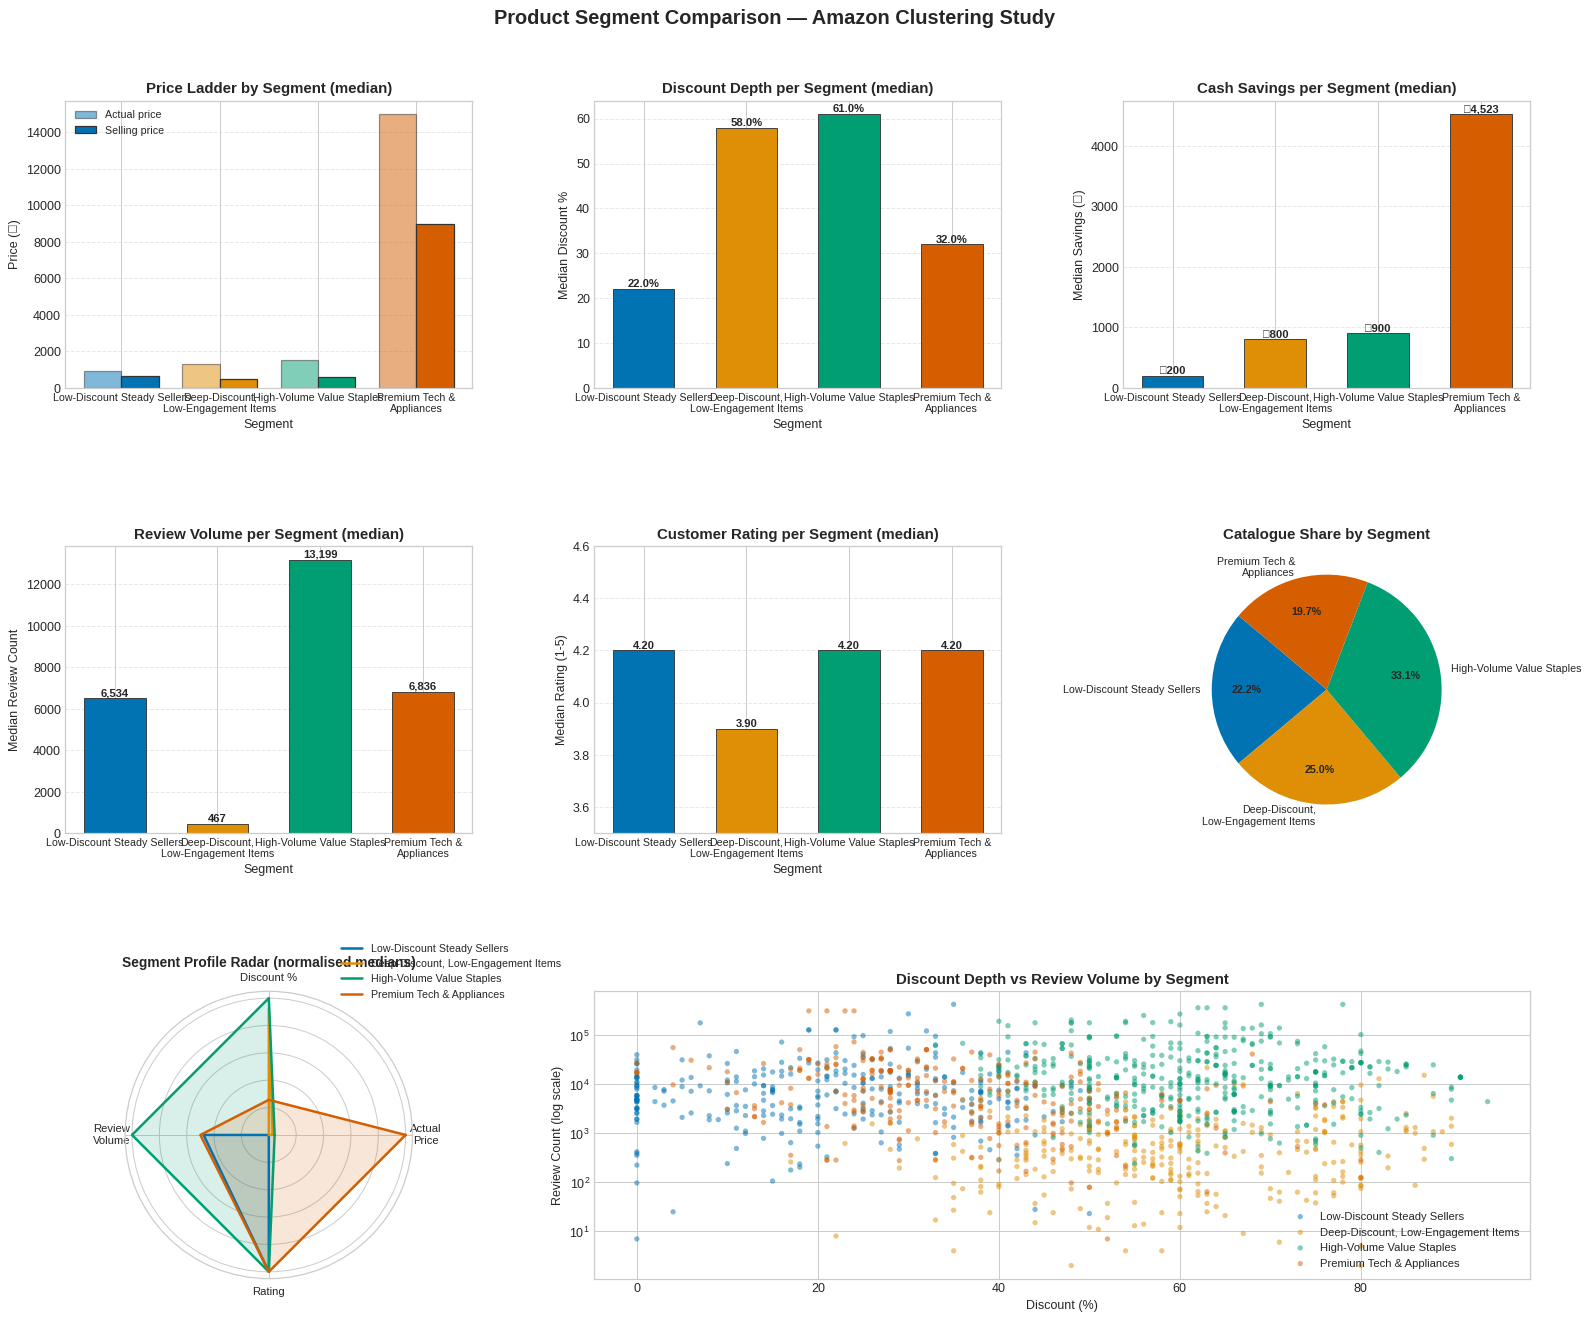

In [28]:
# Segment comparison across commercial dimensions (K-Means k=4)
df_seg = df.copy()
df_seg['Cluster'] = labels_km4
feat_cols = ['discounted_price_clean', 'actual_price_clean', 'discount_percentage_clean',
             'discount_amount', 'rating_clean', 'rating_count_clean']
med = df_seg.groupby('Cluster')[feat_cols].median()
cnt = df_seg.groupby('Cluster').size()
clusters = med.index.tolist()
labels_short = [seg_short[c] for c in clusters]
COLORS = [seg_color[c] for c in clusters]
x = np.arange(len(clusters))
bw = 0.6

fig = plt.figure(figsize=(21, 17))
gs = gridspec.GridSpec(3, 3, figure=fig, hspace=0.55, wspace=0.3)

def style_ax(ax, title, ylabel):
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_ylabel(ylabel)
    ax.set_xlabel('Segment')
    ax.set_xticks(x); ax.set_xticklabels(labels_short, fontsize=8.5)
    ax.grid(axis='y', linestyle='--', alpha=0.45)

def bar_panel(ax, values, fmt, title, ylabel):
    bars = ax.bar(x, values, width=bw, color=COLORS, edgecolor='#333', linewidth=0.7)
    for b in bars:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height(), fmt.format(b.get_height()),
                ha='center', va='bottom', fontsize=9, fontweight='bold')
    style_ax(ax, title, ylabel)

ax1 = fig.add_subplot(gs[0, 0])
w = 0.38
ax1.bar(x - w / 2, med['actual_price_clean'], width=w, color=COLORS, alpha=0.5, edgecolor='#333', label='Actual price')
ax1.bar(x + w / 2, med['discounted_price_clean'], width=w, color=COLORS, edgecolor='#333', label='Selling price')
ax1.legend(fontsize=8.5)
style_ax(ax1, 'Price Ladder by Segment (median)', 'Price (\u20b9)')

bar_panel(fig.add_subplot(gs[0, 1]), med['discount_percentage_clean'], '{:.1f}%', 'Discount Depth per Segment (median)', 'Median Discount %')
bar_panel(fig.add_subplot(gs[0, 2]), med['discount_amount'], '\u20b9{:,.0f}', 'Cash Savings per Segment (median)', 'Median Savings (\u20b9)')
bar_panel(fig.add_subplot(gs[1, 0]), med['rating_count_clean'], '{:,.0f}', 'Review Volume per Segment (median)', 'Median Review Count')
ax5 = fig.add_subplot(gs[1, 1])
bar_panel(ax5, med['rating_clean'], '{:.2f}', 'Customer Rating per Segment (median)', 'Median Rating (1-5)')
ax5.set_ylim(3.5, 4.6)

ax6 = fig.add_subplot(gs[1, 2])
_, _, autotexts = ax6.pie(cnt, labels=[f'{l}' for l in labels_short], colors=COLORS, autopct='%1.1f%%',
                          startangle=140, pctdistance=0.7, textprops={'fontsize': 8.5})
for at in autotexts: at.set_fontweight('bold')
ax6.set_title('Catalogue Share by Segment', fontsize=12, fontweight='bold')

# Radar of four clustering features, min-max normalised across segments
ax7 = fig.add_subplot(gs[2, 0], polar=True)
kpi_labels = ['Actual\nPrice', 'Discount %', 'Review\nVolume', 'Rating']
kpi_raw = np.array([med['actual_price_clean'], med['discount_percentage_clean'],
                    med['rating_count_clean'], med['rating_clean']])
kpi_norm = (kpi_raw - kpi_raw.min(1, keepdims=True)) / (kpi_raw.max(1, keepdims=True) - kpi_raw.min(1, keepdims=True) + 1e-9)
angles = np.linspace(0, 2 * np.pi, len(kpi_labels), endpoint=False).tolist()
angles += angles[:1]
for ci, cid in enumerate(clusters):
    vals = kpi_norm[:, ci].tolist(); vals += vals[:1]
    ax7.plot(angles, vals, color=COLORS[ci], linewidth=2, label=seg_names[cid])
    ax7.fill(angles, vals, color=COLORS[ci], alpha=0.15)
ax7.set_xticks(angles[:-1]); ax7.set_xticklabels(kpi_labels, fontsize=9)
ax7.set_yticklabels([])
ax7.set_title('Segment Profile Radar (normalised medians)', fontsize=11, fontweight='bold', pad=20)
ax7.legend(loc='upper right', bbox_to_anchor=(1.55, 1.2), fontsize=8.5)

# Scatter: discount vs review count (log scale), no fitted lines
ax8 = fig.add_subplot(gs[2, 1:])
for ci, cid in enumerate(clusters):
    m = df_seg['Cluster'] == cid
    ax8.scatter(df_seg.loc[m, 'discount_percentage_clean'], df_seg.loc[m, 'rating_count_clean'],
                color=COLORS[ci], s=18, alpha=0.5, edgecolor='none', label=seg_names[cid])
ax8.set_yscale('log')
ax8.set_xlabel('Discount (%)')
ax8.set_ylabel('Review Count (log scale)')
ax8.set_title('Discount Depth vs Review Volume by Segment', fontsize=12, fontweight='bold')
ax8.legend(fontsize=9, loc='lower right')

fig.suptitle('Product Segment Comparison \u2014 Amazon Clustering Study', fontsize=16, fontweight='bold', y=0.94)
plt.savefig('segment_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

**Observation (Segment comparison):**
Premium products have the largest absolute savings (median ₹4,523) despite a mid-level discount percentage. Value Staples and Deep-Discount items both offer the deepest percentage discounts, but only the Staples attract high review volume. Ratings differ little (3.9 to 4.2), so rating alone is a weak separator. The discount-vs-review scatter (log scale) shows heavy overlap between segments, consistent with the weak silhouette. Medians are used throughout because of the skew.

## 11. Multi-Metric Line Graphs & Feature Profiles
Shows how the metrics change with *k*, and the normalised feature profile of each segment for K-Means and Ward.

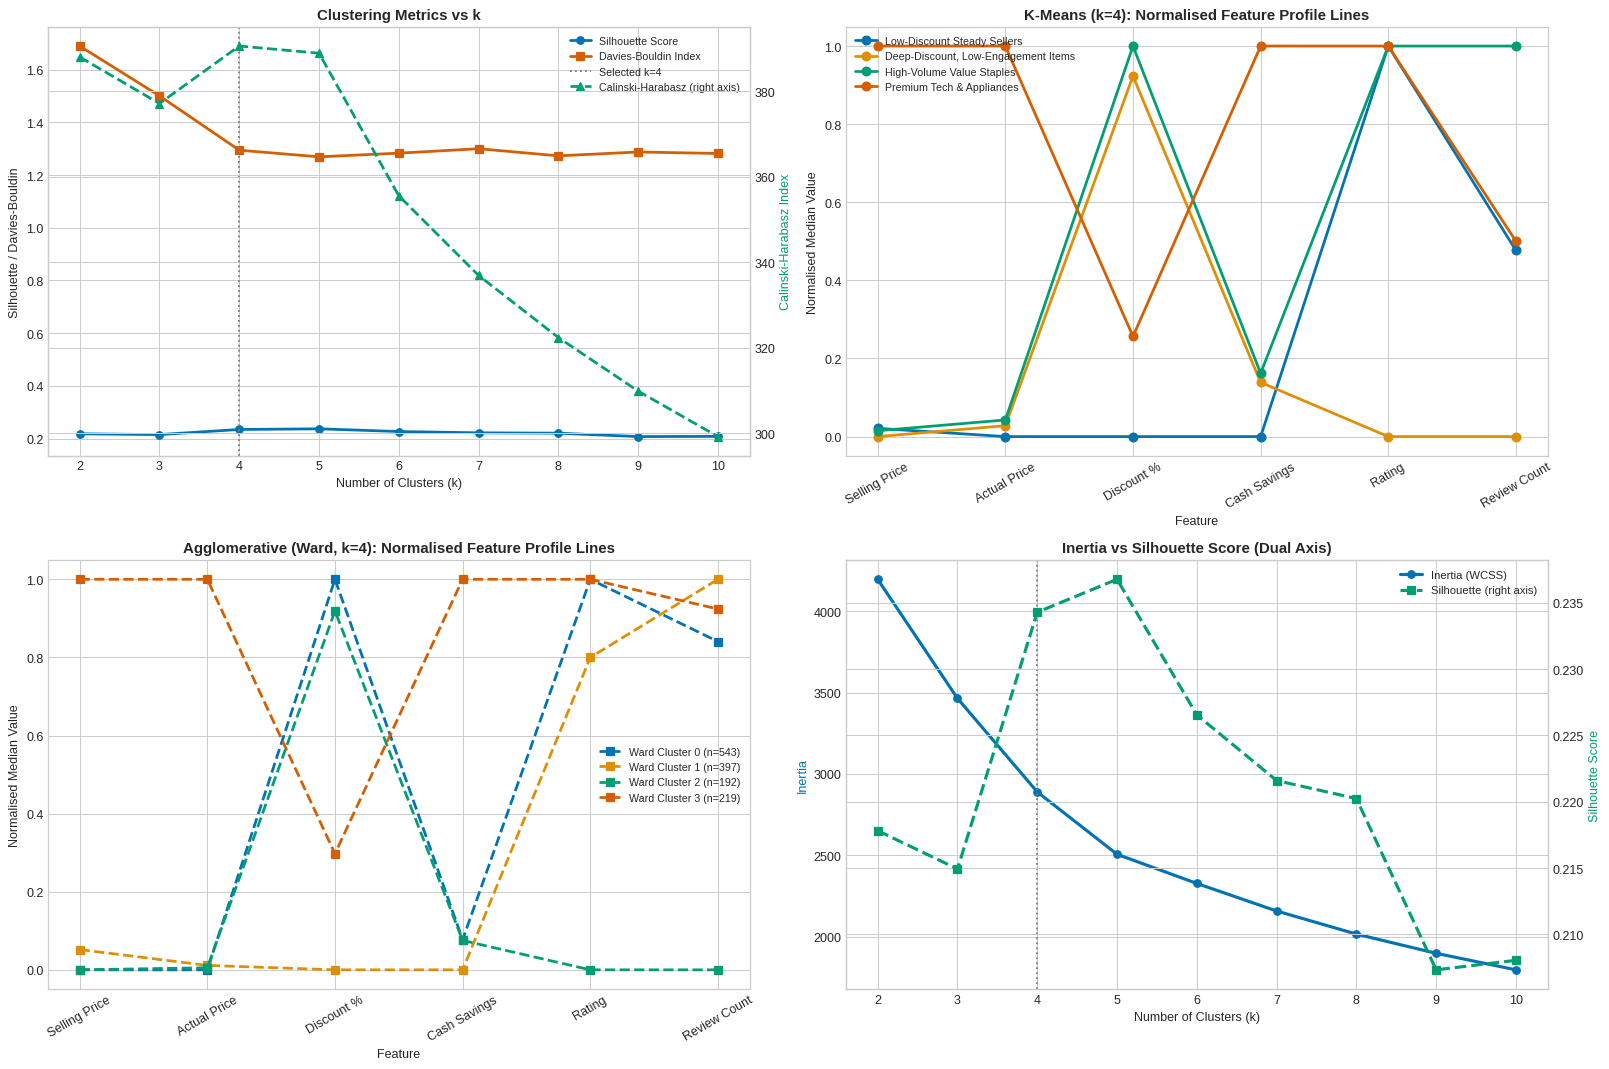

In [29]:
# Multi-metric line graphs and feature-profile lines
fig, axes = plt.subplots(2, 2, figsize=(18, 12))
pretty = ['Selling Price', 'Actual Price', 'Discount %', 'Cash Savings', 'Rating', 'Review Count']

# Plot 1: three validation metrics vs k
ax = axes[0, 0]
ax.plot(list(k_range), silhouette_scores_k, marker='o', linewidth=2.2, color=PALETTE[0], label='Silhouette Score')
ax.plot(list(k_range), davies_bouldin_scores_k, marker='s', linewidth=2.2, color=PALETTE[3], label='Davies-Bouldin Index')
ax_twin = ax.twinx()
ax_twin.plot(list(k_range), calinski_harabasz_scores_k, marker='^', linewidth=2.2, color=PALETTE[2],
             linestyle='--', label='Calinski-Harabasz (right axis)')
ax_twin.set_ylabel('Calinski-Harabasz Index', color=PALETTE[2])
ax.axvline(x=K_PRIMARY, color='grey', linestyle=':', label=f'Selected k={K_PRIMARY}')
ax.set_xlabel('Number of Clusters (k)')
ax.set_ylabel('Silhouette / Davies-Bouldin')
ax.set_title('Clustering Metrics vs k', fontsize=12, fontweight='bold')
ax.set_xticks(list(k_range))
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax_twin.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, fontsize=8.5, loc='upper right')

# Plot 2: K-Means feature profiles
med_line = df_seg.groupby('Cluster')[feat_cols].median()
med_norm = (med_line - med_line.min()) / (med_line.max() - med_line.min() + 1e-9)
ax2 = axes[0, 1]
for cid, row in med_norm.iterrows():
    ax2.plot(pretty, row.values, marker='o', linewidth=2.2, markersize=7, color=seg_color[cid], label=seg_names[cid])
ax2.set_title('K-Means (k=4): Normalised Feature Profile Lines', fontsize=12, fontweight='bold')
ax2.set_xlabel('Feature')
ax2.set_ylabel('Normalised Median Value')
ax2.legend(fontsize=8.5)
ax2.tick_params(axis='x', rotation=30)

# Plot 3: Ward feature profiles
df_w = df.copy(); df_w['Cluster'] = agg_labels['ward']
med_w = df_w.groupby('Cluster')[feat_cols].median()
med_w_norm = (med_w - med_w.min()) / (med_w.max() - med_w.min() + 1e-9)
ax3 = axes[1, 0]
for cid, row in med_w_norm.iterrows():
    ax3.plot(pretty, row.values, marker='s', linewidth=2.2, markersize=7, color=PALETTE[cid], linestyle='--',
             label=f'Ward Cluster {cid} (n={(agg_labels["ward"] == cid).sum()})')
ax3.set_title('Agglomerative (Ward, k=4): Normalised Feature Profile Lines', fontsize=12, fontweight='bold')
ax3.set_xlabel('Feature')
ax3.set_ylabel('Normalised Median Value')
ax3.legend(fontsize=8.5)
ax3.tick_params(axis='x', rotation=30)

# Plot 4: inertia and silhouette, dual axis
ax4 = axes[1, 1]
ax4.plot(list(k_range), inertias, marker='o', linewidth=2.5, color=PALETTE[0], label='Inertia (WCSS)')
ax4.set_xlabel('Number of Clusters (k)')
ax4.set_ylabel('Inertia', color=PALETTE[0])
ax4b = ax4.twinx()
ax4b.plot(list(k_range), silhouette_scores_k, marker='s', linewidth=2.5, color=PALETTE[2], linestyle='--', label='Silhouette (right axis)')
ax4b.set_ylabel('Silhouette Score', color=PALETTE[2])
ax4.axvline(x=K_PRIMARY, color='grey', linestyle=':')
ax4.set_xticks(list(k_range))
ha, la = ax4.get_legend_handles_labels(); hb, lb = ax4b.get_legend_handles_labels()
ax4.legend(ha + hb, la + lb, fontsize=9)
ax4.set_title('Inertia vs Silhouette Score (Dual Axis)', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig('line_graphs_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

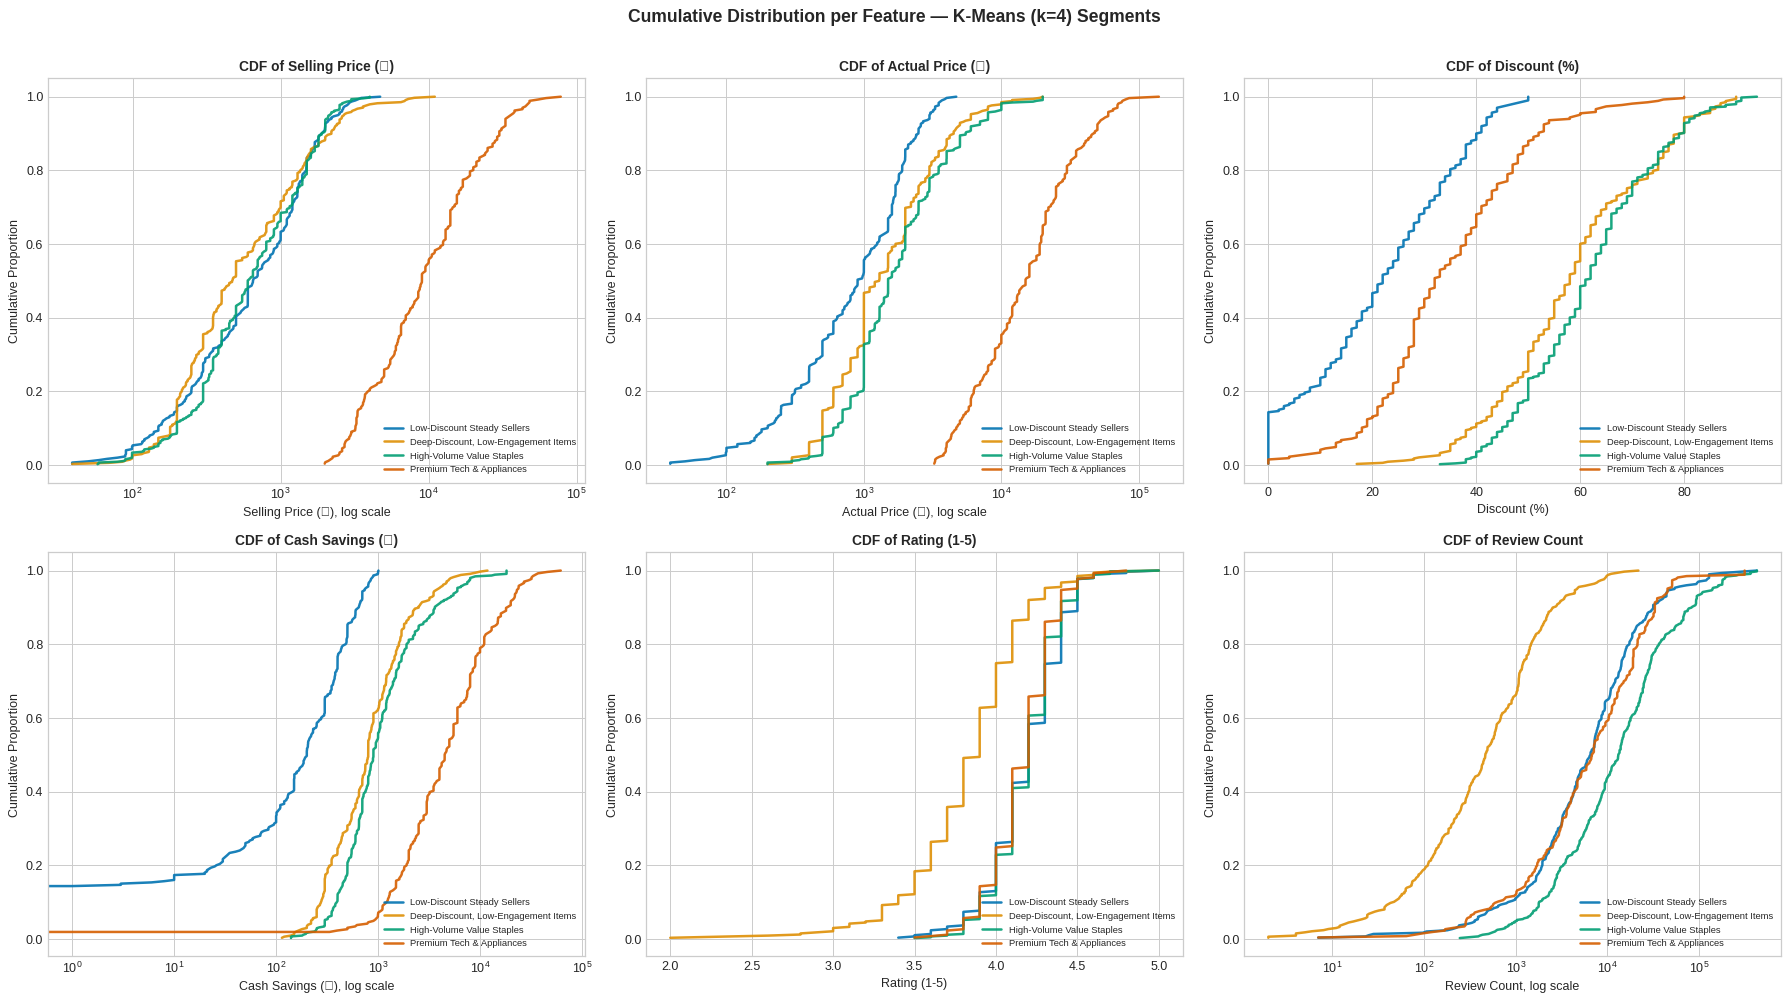

In [30]:
# Cumulative distribution of each feature per K-Means (k=4) segment
fig, axes = plt.subplots(2, 3, figsize=(20, 11))
pretty_units = ['Selling Price (\u20b9)', 'Actual Price (\u20b9)', 'Discount (%)',
                'Cash Savings (\u20b9)', 'Rating (1-5)', 'Review Count']
for ax, feat, ptitle in zip(axes.flatten(), feat_cols, pretty_units):
    for cid in sorted(df_seg['Cluster'].unique()):
        vals = df_seg.loc[df_seg['Cluster'] == cid, feat].dropna().sort_values()
        ax.plot(vals, np.arange(1, len(vals) + 1) / len(vals), linewidth=2, color=seg_color[cid],
                label=seg_names[cid], alpha=0.9)
    if feat in ('discounted_price_clean', 'actual_price_clean', 'discount_amount', 'rating_count_clean'):
        ax.set_xscale('log')
        ptitle_x = ptitle + ', log scale'
    else:
        ptitle_x = ptitle
    ax.set_title(f'CDF of {ptitle}', fontsize=11, fontweight='bold')
    ax.set_xlabel(ptitle_x)
    ax.set_ylabel('Cumulative Proportion')
    ax.legend(fontsize=7.5, loc='lower right')
fig.suptitle('Cumulative Distribution per Feature \u2014 K-Means (k=4) Segments', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('cdf_lines_per_cluster.png', dpi=150, bbox_inches='tight')
plt.show()

**Observation (Line graphs & CDFs):**
The metric curves are flat between k = 4 and k = 6 (silhouette 0.227–0.237, Davies-Bouldin 1.27–1.29), which confirms that the choice of k in this range is not sharp. The profile lines show the same four archetypes for K-Means as in Section 9. The CDF curves show that segments overlap on rating but separate clearly on actual price (Premium) and review count (Deep-Discount versus Value Staples).

## 12. Conclusion

**Summary**
- Pipeline: 1,465 review rows → 1,351 unique products; features parsed, log-transformed, de-correlated and standardised; two algorithms evaluated with three metrics.
- **Best model: K-Means with k = 4** (rank 1 on Silhouette 0.234, Davies-Bouldin 1.295 and Calinski-Harabasz 390.6). Ward hierarchical clustering at k = 4 is the best hierarchical result (0.194 / 1.485 / 324.6) and its dendrogram independently supports four clusters.
- The four segments are Premium Tech & Appliances, High-Volume Value Staples, Deep-Discount Low-Engagement Items, and Low-Discount Steady Sellers. They are nearly independent of the retail category (ARI 0.057).

**Limitations**
- Silhouette scores below 0.25 indicate weak, overlapping structure; segments are tendencies, not sharply separated groups.
- k = 4 and k = 5 are almost tied on the metrics, so k = 4 was chosen for parsimony and interpretability.
- Complete and Average linkage were sensitive to outliers and gave degenerate partitions; trimming outliers or using a robust scaler is a possible extension.
- Missing values were median-filled; the dataset is a single snapshot, so no trends over time can be claimed.

**Possible extensions:** Gaussian mixtures or DBSCAN, a robust scaler, and including text features from the product descriptions.

## Review 2 Deliverables & Rubric Check

| Code | Criterion | Where it is addressed |
|:---|:---|:---|
| **B1** Implementation | K-Means and Agglomerative clustering fitted, labels obtained | Sections 4 and 5; all cells run top to bottom with outputs |
| **B2** Evaluation metrics | Silhouette, Davies-Bouldin, Calinski-Harabasz for all configurations; Elbow curve and Dendrogram | Section 4 (elbow), Section 5 (dendrogram), Section 6 (metrics table and charts) |
| **B2/A3** Best model | Best model chosen with justification | Section 7 (rank table, like-for-like comparison, caveats) |
| **B3** Cluster visualisation | PCA scatter for every configuration; t-SNE for at least one; biplot | Section 8 (PCA grid for all 6 configurations, t-SNE for 2 models, biplot) |
| **§3.3** Ground-truth rule | Labels only used after fitting | Section 9: category labels used only for post-hoc ARI/NMI and cross-tab |
| **§7.1** Reproducibility | `random_state=42`, no leakage, Markdown explanations | Section 1 sets the seed; scaling note in Section 3; observation cell after each major output |

---
*End of Clustering Track Notebook — Machine Learning Capstone Review 2.*